# Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

import os
import re
from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter, PercentFormatter
import seaborn as sns
import plotly.subplots as sp
import plotly.express as px
from concurrent.futures import ThreadPoolExecutor
from colorama import Fore, Style
from IPython.display import clear_output
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.options.display.max_columns = None

from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import StratifiedKFold
from scipy.optimize import minimize
from sklearn.ensemble import VotingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import train_test_split
import os
import torch

from keras.models import Model
from keras.layers import Input, Dense
from keras.optimizers import Adam

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

## Load data

In [2]:
train = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/train.csv')
test = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/test.csv')
data_dict = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/data_dictionary.csv')
train.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMC,BIA-BIA_BMI,BIA-BIA_BMR,BIA-BIA_DEE,BIA-BIA_ECW,BIA-BIA_FFM,BIA-BIA_FFMI,BIA-BIA_FMI,BIA-BIA_Fat,BIA-BIA_Frame_num,BIA-BIA_ICW,BIA-BIA_LDM,BIA-BIA_LST,BIA-BIA_SMM,BIA-BIA_TBW,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,PCIAT-Season,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,Fall,2.0,2.66855,16.8792,932.498,1492.00,8.25598,41.5862,13.8177,3.06143,9.21377,1.0,24.4349,8.89536,38.9177,19.5413,32.6909,NaN,NaN,NaN,NaN,Fall,5.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,22.0,75.0,70.0,122.0,NaN,NaN,NaN,NaN,Fall,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,Winter,2.0,2.57949,14.0371,936.656,1498.65,6.01993,42.0291,12.8254,1.21172,3.97085,1.0,21.0352,14.97400,39.4497,15.4107,27.0552,NaN,NaN,Fall,2.340,Fall,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,NaN,65.0,94.0,117.0,Fall,5.0,7.0,33.0,Fall,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,2.170,Fall,5.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,NaN,60.0,97.0,117.0,Summer,6.0,9.0,37.0,Summer,18.0,1.0,NaN,NaN,NaN,NaN,5.0,0.0,7.0,0.0,7.0,0.0,7.0,1.0,Summer,3.0,3.84191,18.2943,1131.430,1923.44,15.59250,62.7757,14.0740,4.22033,18.82430,2.0,30.4041,16.77900,58.9338,26.4798,45.9966,NaN,NaN,Winter,2.451,Summer,4.0,2.0,4.0,0.0,5.0,1.0,0.0,3.0,2.0,2.0,3.0,0.0,3.0,0.0,0.0,3.0,4.0,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,1.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
test.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMC,BIA-BIA_BMI,BIA-BIA_BMR,BIA-BIA_DEE,BIA-BIA_ECW,BIA-BIA_FFM,BIA-BIA_FFMI,BIA-BIA_FMI,BIA-BIA_Fat,BIA-BIA_Frame_num,BIA-BIA_ICW,BIA-BIA_LDM,BIA-BIA_LST,BIA-BIA_SMM,BIA-BIA_TBW,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,Fall,2.0,2.66855,16.8792,932.498,1492.00,8.25598,41.5862,13.8177,3.06143,9.21377,1.0,24.4349,8.89536,38.9177,19.5413,32.6909,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,3.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,22.0,75.0,70.0,122.0,NaN,NaN,NaN,NaN,Fall,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,Winter,2.0,2.57949,14.0371,936.656,1498.65,6.01993,42.0291,12.8254,1.21172,3.97085,1.0,21.0352,14.97400,39.4497,15.4107,27.0552,NaN,NaN,Fall,2.340,Fall,46.0,64.0,Summer,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,NaN,65.0,94.0,117.0,Fall,5.0,7.0,33.0,Fall,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,2.170,Fall,38.0,54.0,Summer,2.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,NaN,60.0,97.0,117.0,Summer,6.0,9.0,37.0,Summer,18.0,1.0,NaN,NaN,NaN,NaN,5.0,0.0,7.0,0.0,7.0,0.0,7.0,1.0,Summer,3.0,3.84191,18.2943,1131.430,1923.44,15.59250,62.7757,14.0740,4.22033,18.82430,2.0,30.4041,16.77900,58.9338,26.4798,45.9966,NaN,NaN,Winter,2.451,Summer,31.0,45.0,Winter,0.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,1.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Target

In [4]:
train_cols = set(train.columns)
test_cols = set(test.columns)
columns_not_in_test = sorted(list(train_cols - test_cols))

columns_to_exclude = ['PCIAT-PCIAT_Total', 'PCIAT-Season', 'sii']
question_columns = [
    col for col in columns_not_in_test if col not in columns_to_exclude
]

question_columns

['PCIAT-PCIAT_01',
 'PCIAT-PCIAT_02',
 'PCIAT-PCIAT_03',
 'PCIAT-PCIAT_04',
 'PCIAT-PCIAT_05',
 'PCIAT-PCIAT_06',
 'PCIAT-PCIAT_07',
 'PCIAT-PCIAT_08',
 'PCIAT-PCIAT_09',
 'PCIAT-PCIAT_10',
 'PCIAT-PCIAT_11',
 'PCIAT-PCIAT_12',
 'PCIAT-PCIAT_13',
 'PCIAT-PCIAT_14',
 'PCIAT-PCIAT_15',
 'PCIAT-PCIAT_16',
 'PCIAT-PCIAT_17',
 'PCIAT-PCIAT_18',
 'PCIAT-PCIAT_19',
 'PCIAT-PCIAT_20']


The task is to predict the internet addiction status (SII) of a group of people. In the training dataset, participants answer 20 questions (PCIAT-PCIAT_1, PCIAT-PCIAT_2, ..., PCIAT-PCIAT_20), where each question is rated from 0 to 5, with 0 indicating no severity and 5 indicating the highest severity. The total score from these 20 questions is calculated in the column PCIAT-PCIAT_Total and mapped to the target column, SII, which has values ranging from 0 to 3. This is the column that needs to be predicted.

## Filter rows with ambigious sii


There are many survey participants who did not answer some questions, or there were errors in data collection. These rows could cause the total score to change when those questions are answered, making the SII unclear. Filter out the rows where the SII is unclear

In [5]:
def recalculate_sii(row):
    if pd.isna(row['PCIAT-PCIAT_Total']):
        return np.nan
    max_possible = row['PCIAT-PCIAT_Total'] + row[question_columns].isna().sum() * 5
    if row['PCIAT-PCIAT_Total'] <= 30 and max_possible <= 30:
        return 0
    elif 31 <= row['PCIAT-PCIAT_Total'] <= 49 and max_possible <= 49:
        return 1
    elif 50 <= row['PCIAT-PCIAT_Total'] <= 79 and max_possible <= 79:
        return 2
    elif row['PCIAT-PCIAT_Total'] >= 80 and max_possible >= 80:
        return 3
    return np.nan

train['recalc_sii'] = train.apply(recalculate_sii, axis=1)

In [6]:
mismatch_rows = train[
    (train['recalc_sii'] != train['sii']) & train['sii'].notna()
]

mismatch_rows[question_columns + ['recalc_sii']].style.map(
    lambda x: 'background-color: #FFC0CB' if pd.isna(x) else ''
)

,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,recalc_sii
24,2.000000,2.000000,3.000000,1.000000,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000,2.000000,nan,2.000000,nan
93,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
104,5.000000,2.000000,4.000000,2.000000,nan,2.000000,2.000000,2.000000,1.000000,2.000000,1.000000,1.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,nan
141,1.000000,2.000000,4.000000,2.000000,2.000000,2.000000,1.000000,3.000000,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000,3.000000,0.000000,nan,0.000000,2.000000,0.000000,nan
142,2.000000,2.000000,2.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,1.000000,3.000000,0.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,nan,1.000000,nan
270,3.000000,3.000000,4.000000,2.000000,4.000000,2.000000,1.000000,3.000000,2.000000,2.000000,4.000000,0.000000,2.000000,1.000000,4.000000,nan,2.000000,3.000000,4.000000,2.000000,nan
368,2.000000,3.000000,4.000000,2.000000,5.000000,1.000000,2.000000,nan,nan,nan,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,2.000000,1.000000,nan,nan,nan
592,3.000000,0.000000,3.000000,0.000000,3.000000,1.000000,0.000000,1.000000,1.000000,1.000000,2.000000,0.000000,1.000000,nan,nan,1.000000,2.000000,1.000000,1.000000,0.000000,nan
724,3.000000,2.000000,4.000000,2.000000,2.000000,1.000000,0.000000,nan,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,3.000000,0.000000,1.000000,nan
877,5.000000,5.000000,5.000000,4.000000,5.000000,0.000000,5.000000,5.000000,5.000000,5.000000,4.000000,nan,4.000000,5.000000,5.000000,1.000000,5.000000,0.000000,5.000000,5.000000,nan


These rows have ambigious sii values => Drop

In [7]:
train['sii'] = train['recalc_sii']
train = train.drop(mismatch_rows.index)

train[columns_not_in_test + ['recalc_sii']]

,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,PCIAT-Season,sii,recalc_sii
0,5.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,4.0,55.0,Fall,2.0,2.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Fall,0.0,0.0
2,5.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,28.0,Fall,0.0,0.0
3,4.0,2.0,4.0,0.0,5.0,1.0,0.0,3.0,2.0,2.0,3.0,0.0,3.0,0.0,0.0,3.0,4.0,3.0,4.0,1.0,44.0,Summer,1.0,1.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3955,3.0,3.0,3.0,2.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,0.0,2.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,32.0,Winter,1.0,1.0
3956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3957,5.0,5.0,3.0,0.0,5.0,1.0,0.0,2.0,0.0,2.0,1.0,0.0,1.0,3.0,0.0,0.0,1.0,1.0,0.0,1.0,31.0,Winter,1.0,1.0
3958,2.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,2.0,0.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,19.0,Spring,0.0,0.0


In [8]:
na_total_rows = train[train['sii'].isna()]
na_total_rows

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMC,BIA-BIA_BMI,BIA-BIA_BMR,BIA-BIA_DEE,BIA-BIA_ECW,BIA-BIA_FFM,BIA-BIA_FFMI,BIA-BIA_FMI,BIA-BIA_Fat,BIA-BIA_Frame_num,BIA-BIA_ICW,BIA-BIA_LDM,BIA-BIA_LST,BIA-BIA_SMM,BIA-BIA_TBW,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,PCIAT-Season,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,recalc_sii
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,1.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0068a485,Fall,10,1,NaN,NaN,Fall,16.861286,59.25,84.2,27.0,71.0,90.0,116.0,NaN,NaN,NaN,NaN,Fall,0.0,0.0,12.6,2.0,11.1,1.0,0.0,0.0,0.0,0.0,0.00,0.0,4.0,0.0,Fall,3.0,4.05726,16.8631,1180.04,1888.06,21.94,67.9527,13.6092,3.25395,16.2474,2.0,28.5367,17.476,63.8954,28.768,50.4767,NaN,NaN,Fall,1.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,2.0,NaN,NaN
8,0069fbed,Summer,15,0,NaN,NaN,Spring,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,2.0,NaN,NaN
9,0083e397,Summer,19,1,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,0087dd65,Spring,11,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3943,fe7c87e2,Spring,13,0,Summer,NaN,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,1.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3944,fe7f68a7,Spring,15,1,NaN,NaN,Spring,22.457960,62.00,122.8,30.0,64.0,60.0,106.0,NaN,NaN,NaN,NaN,Summer,9.0,0.0,18.5,2.0,21.8,2.0,0.0,0.0,8.0,0.0,8.75,0.0,9.5,1.0,Summer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We decided to drop all rows where the SII cannot be calculated, as no questions were answered

In [9]:
train = train.dropna(subset=['PCIAT-PCIAT_Total'])
train

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMC,BIA-BIA_BMI,BIA-BIA_BMR,BIA-BIA_DEE,BIA-BIA_ECW,BIA-BIA_FFM,BIA-BIA_FFMI,BIA-BIA_FMI,BIA-BIA_Fat,BIA-BIA_Frame_num,BIA-BIA_ICW,BIA-BIA_LDM,BIA-BIA_LST,BIA-BIA_SMM,BIA-BIA_TBW,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,PCIAT-Season,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,recalc_sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,Fall,2.0,2.66855,16.8792,932.498,1492.00,8.25598,41.5862,13.8177,3.061430,9.21377,1.0,24.4349,8.89536,38.9177,19.5413,32.6909,NaN,NaN,NaN,NaN,Fall,5.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,22.0,75.0,70.0,122.0,NaN,NaN,NaN,NaN,Fall,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,Winter,2.0,2.57949,14.0371,936.656,1498.65,6.01993,42.0291,12.8254,1.211720,3.97085,1.0,21.0352,14.97400,39.4497,15.4107,27.0552,NaN,NaN,Fall,2.340,Fall,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,NaN,65.0,94.0,117.0,Fall,5.0,7.0,33.0,Fall,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,2.170,Fall,5.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,NaN,60.0,97.0,117.0,Summer,6.0,9.0,37.0,Summer,18.0,1.0,NaN,NaN,NaN,NaN,5.0,0.0,7.0,0.0,7.0,0.0,7.0,1.0,Summer,3.0,3.84191,18.2943,1131.430,1923.44,15.59250,62.7757,14.0740,4.220330,18.82430,2.0,30.4041,16.77900,58.9338,26.4798,45.9966,NaN,NaN,Winter,2.451,Summer,4.0,2.0,4.0,0.0,5.0,1.0,0.0,3.0,2.0,2.0,3.0,0.0,3.0,0.0,0.0,3.0,4.0,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0,1.0
5,001f3379,Spring,13,1,Winter,50.0,Summer,22.279952,59.5,112.2,NaN,60.0,73.0,102.0,NaN,NaN,NaN,NaN,Summer,12.0,0.0,16.5,2.0,17.9,2.0,6.0,0.0,10.0,1.0,11.0,1.0,8.0,0.0,Summer,2.0,4.33036,30.1865,1330.970,1996.45,30.21240,84.0285,16.6877,13.498800,67.97150,2.0,32.9141,20.90200,79.6982,35.3804,63.1265,NaN,NaN,Spring,4.110,Summer,3.0,3.0,3.0,0.0,2.0,1.0,0.0,2.0,2.0,1.0,0.0,1.0,3.0,3.0,2.0,1.0,3.0,1.0,2.0,1.0,34.0,Summer,40.0,56.0,Spring,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3953,ff6c2bb8,Fall,8,0,NaN,NaN,Fall,17.139810,52.5,67.2,25.0,60.0,65.0,112.0,NaN,NaN,NaN,NaN,Fall,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,8.0,1.0,10.0,1.0,12.0,1.0,Fall,3.0,3.20303,17.1417,1035.270,1759.96,11.00630,52.5331,13.4004,3.741300,14.66690,1.0,25.7118,15.81500,

For the remaining rows, fill the unanswered questions with the mode of the corresponding column.

In [10]:
for column in question_columns:
    if train[column].isna().any():
        mode_value = train[column].mode()[0]
        train[column] = train[column].fillna(mode_value)

train[columns_not_in_test + ['recalc_sii']]

,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,PCIAT-Season,sii,recalc_sii
0,5.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,4.0,55.0,Fall,2.0,2.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Fall,0.0,0.0
2,5.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,28.0,Fall,0.0,0.0
3,4.0,2.0,4.0,0.0,5.0,1.0,0.0,3.0,2.0,2.0,3.0,0.0,3.0,0.0,0.0,3.0,4.0,3.0,4.0,1.0,44.0,Summer,1.0,1.0
5,3.0,3.0,3.0,0.0,2.0,1.0,0.0,2.0,2.0,1.0,0.0,1.0,3.0,3.0,2.0,1.0,3.0,1.0,2.0,1.0,34.0,Summer,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3953,3.0,3.0,3.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,3.0,0.0,2.0,2.0,1.0,22.0,Fall,0.0,0.0
3954,1.0,3.0,3.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,5.0,1.0,0.0,5.0,3.0,3.0,3.0,0.0,33.0,Summer,1.0,1.0
3955,3.0,3.0,3.0,2.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,0.0,2.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,32.0,Winter,1.0,1.0
3957,5.0,5.0,3.0,0.0,5.0,1.0,0.0,2.0,0.0,2.0,1.0,0.0,1.0,3.0,0.0,0.0,1.0,1.0,0.0,1.0,31.0,Winter,1.0,1.0


In [11]:
train.drop(columns='recalc_sii', inplace=True)

train[columns_not_in_test]

,PCIAT-PCIAT_01,PCIAT-PCIAT_02,PCIAT-PCIAT_03,PCIAT-PCIAT_04,PCIAT-PCIAT_05,PCIAT-PCIAT_06,PCIAT-PCIAT_07,PCIAT-PCIAT_08,PCIAT-PCIAT_09,PCIAT-PCIAT_10,PCIAT-PCIAT_11,PCIAT-PCIAT_12,PCIAT-PCIAT_13,PCIAT-PCIAT_14,PCIAT-PCIAT_15,PCIAT-PCIAT_16,PCIAT-PCIAT_17,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,PCIAT-Season,sii
0,5.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,4.0,55.0,Fall,2.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Fall,0.0
2,5.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,28.0,Fall,0.0
3,4.0,2.0,4.0,0.0,5.0,1.0,0.0,3.0,2.0,2.0,3.0,0.0,3.0,0.0,0.0,3.0,4.0,3.0,4.0,1.0,44.0,Summer,1.0
5,3.0,3.0,3.0,0.0,2.0,1.0,0.0,2.0,2.0,1.0,0.0,1.0,3.0,3.0,2.0,1.0,3.0,1.0,2.0,1.0,34.0,Summer,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3953,3.0,3.0,3.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,3.0,0.0,2.0,2.0,1.0,22.0,Fall,0.0
3954,1.0,3.0,3.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,5.0,1.0,0.0,5.0,3.0,3.0,3.0,0.0,33.0,Summer,1.0
3955,3.0,3.0,3.0,2.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,0.0,2.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,32.0,Winter,1.0
3957,5.0,5.0,3.0,0.0,5.0,1.0,0.0,2.0,0.0,2.0,1.0,0.0,1.0,3.0,0.0,0.0,1.0,1.0,0.0,1.0,31.0,Winter,1.0


## Helper functions

In [12]:
def calculate_stats(data, columns):
    if isinstance(columns, str):
        columns = [columns]

    stats = []
    for col in columns:
        if data[col].dtype in ['object', 'category']:
            counts = data[col].value_counts(dropna=False, sort=False)
            percents = data[col].value_counts(normalize=True, dropna=False, sort=False) * 100
            formatted = counts.astype(str) + ' (' + percents.round(2).astype(str) + '%)'
            stats_col = pd.DataFrame({'count (%)': formatted})
            stats.append(stats_col)
        else:
            stats_col = data[col].describe().to_frame().transpose()
            stats_col['missing'] = data[col].isnull().sum()
            stats_col.index.name = col
            stats.append(stats_col)

    return pd.concat(stats, axis=0)

- **quadratic_weigthed_kappa**: Hàm tính điểm có trọng số. Đây là hàm được dùng tính điểm trong yêu cầu đề bài
- **threshold_Rounder**: Hàm làm tròn dựa trên thresholds đã được customize. Thay vì làm tròn ở 0.5, 1.5 và 2.5, chúng ta có thể tự tính ngưỡng làm tròn sao cho mô hình hoạt động tốt nhất.
- **evaluate_predictions**: Hàm này đánh giá điểm của mô hình dựa trên thresholds, sử dụng hàm threshold_Rounder để làm tròn giá trị dự đoán, sau đó tính điểm Kappa. Dùng để tối ưu hóa trong quá trình cải thiện mô hình.
- **trainML**: Hàm huấn luyện mô hình với StratifiedKFold. Fit từng fold, tính ngưỡng làm tròn tối ưu cho sau khi huấn luyện qua tất cả các fold, và dự đoán trên tập test, trả về kết quả dự đoán và ô hình đã fit

In [13]:
def quadratic_weighted_kappa(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights='quadratic')

def threshold_Rounder(oof_non_rounded, thresholds):
    return np.where(oof_non_rounded < thresholds[0], 0,
                    np.where(oof_non_rounded < thresholds[1], 1,
                             np.where(oof_non_rounded < thresholds[2], 2, 3)))

def evaluate_predictions(thresholds, y_true, oof_non_rounded):
    rounded_p = threshold_Rounder(oof_non_rounded, thresholds)
    return -quadratic_weighted_kappa(y_true, rounded_p)

def TrainML(model_class, train_data, test_data):
    
    X = train_data.drop(['sii'], axis=1)
    y = train_data['sii']

    SKF = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    
    train_S = []
    test_S = []
    
    oof_non_rounded = np.zeros(len(y), dtype=float) 
    oof_rounded = np.zeros(len(y), dtype=int) 
    test_preds = np.zeros((len(test_data), n_splits))

    for fold, (train_idx, test_idx) in enumerate(tqdm(SKF.split(X, y), desc="Training Folds", total=n_splits)):
        X_train, X_val = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[test_idx]

        model = clone(model_class)
        model.fit(X_train, y_train)

        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)

        oof_non_rounded[test_idx] = y_val_pred
        y_val_pred_rounded = y_val_pred.round(0).astype(int)
        oof_rounded[test_idx] = y_val_pred_rounded

        train_kappa = quadratic_weighted_kappa(y_train, y_train_pred.round(0).astype(int))
        val_kappa = quadratic_weighted_kappa(y_val, y_val_pred_rounded)

        train_S.append(train_kappa)
        test_S.append(val_kappa)
        
        test_preds[:, fold] = model.predict(test_data)
        
        print(f"Fold {fold+1} - Train QWK: {train_kappa:.4f}, Validation QWK: {val_kappa:.4f}")
        clear_output(wait=True)

    print(f"Mean Train QWK --> {np.mean(train_S):.4f}")
    print(f"Mean Validation QWK ---> {np.mean(test_S):.4f}")

    KappaOPtimizer = minimize(evaluate_predictions,
                              x0=[0.5, 1.5, 2.5], args=(y, oof_non_rounded), 
                              method='Nelder-Mead') # Nelder-Mead | # Powell
    assert KappaOPtimizer.success, "Optimization did not converge."
    
    oof_tuned = threshold_Rounder(oof_non_rounded, KappaOPtimizer.x)
    tKappa = quadratic_weighted_kappa(y, oof_tuned)

    print(f"----> || Optimized QWK SCORE :: {Fore.CYAN}{Style.BRIGHT} {tKappa:.3f}{Style.RESET_ALL}")

    tpm = test_preds.mean(axis=1)
    tpTuned = threshold_Rounder(tpm, KappaOPtimizer.x)
    
    submission = pd.DataFrame({
        'id': sample['id'],
        'sii': tpTuned
    })

    return submission,model

#  Data cleaning

The group's approach will be to assess the importance of each column with respect to SII to decide whether to keep or discard it. Next, we will examine its relationship with other columns in the training dataset, primarily age, sex, and season, as these columns already contain sufficient information. We will use these columns to predict missing values for the important ones. Then, we will analyze the relationship of these columns with the PCIAT-PCIAT_Total column to identify any notable patterns. 

Columns that cannot be filled due to insufficient relationships with reliable columns will be left intact

## Age

Add Age Group columns

In [14]:
import pandas as pd

def apply_age_group(df):
    df['Age Group'] = pd.cut(
        df['Basic_Demos-Age'],
        bins=[4, 12, 18, 22],
        labels=['Children', 'Adolescents', 'Adults'],
    )
    return df

train = apply_age_group(train)
test = apply_age_group(test)

In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
train['Age_Group_Label'] = le.fit_transform(train['Age Group'])
test['Age_Group_Label'] = le.fit_transform(test['Age Group'])
train[['Age Group', 'Age_Group_Label']]

,Age Group,Age_Group_Label
0,Children,2
1,Children,2
2,Children,2
3,Children,2
5,Adolescents,0
...,...,...
3953,Children,2
3954,Children,2
3955,Adolescents,0
3957,Children,2


In [16]:
calculate_stats(train, ['Basic_Demos-Age'])

,count,mean,std,min,25%,50%,75%,max,missing
Basic_Demos-Age,,,,,,,,,
Basic_Demos-Age,2719.0,10.225451,3.419461,5.0,8.0,10.0,12.0,22.0,0


## CGAS score

###  CGAS-Season

In [17]:
calculate_stats(train, 'CGAS-Season')

,count (%)
CGAS-Season,
Winter,535 (19.68%)
NaN,391 (14.38%)
Fall,575 (21.15%)
Summer,555 (20.41%)
Spring,663 (24.38%)


Fill missing season values by ratio of each season's occurences in train data

In [18]:
season_counts = train['CGAS-Season'].value_counts(normalize=True)

train['CGAS-Season'] = train['CGAS-Season'].apply(
    lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x
)
test['CGAS-Season'] = test['CGAS-Season'].apply(
    lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x
)
calculate_stats(train, 'CGAS-Season')

,count (%)
CGAS-Season,
Winter,622 (22.88%)
Fall,667 (24.53%)
Summer,656 (24.13%)
Spring,774 (28.47%)


### CGAS Score

In [19]:
calculate_stats(train, 'CGAS-CGAS_Score')

,count,mean,std,min,25%,50%,75%,max,missing
CGAS-CGAS_Score,,,,,,,,,
CGAS-CGAS_Score,2328.0,65.145189,11.81724,25.0,59.0,65.0,75.0,95.0,391


Drop the outlier with CGAS score = 999

In [20]:
train.loc[train['CGAS-CGAS_Score'] == 999, 'CGAS-CGAS_Score'] = np.nan

In [21]:
calculate_stats(train, 'CGAS-CGAS_Score')

,count,mean,std,min,25%,50%,75%,max,missing
CGAS-CGAS_Score,,,,,,,,,
CGAS-CGAS_Score,2328.0,65.145189,11.81724,25.0,59.0,65.0,75.0,95.0,391


Check relationshoip with age and sex

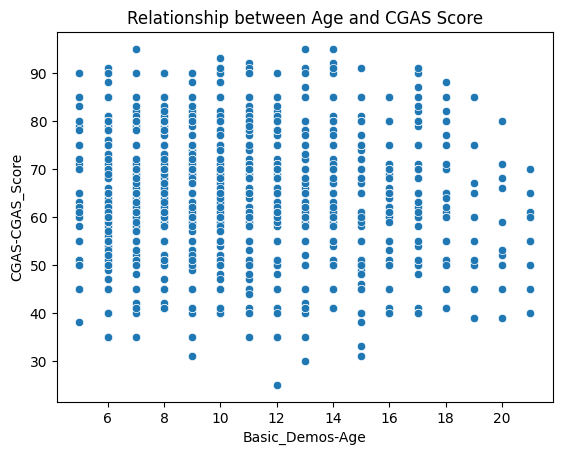

In [22]:
sns.scatterplot(data=train, x='Basic_Demos-Age', y='CGAS-CGAS_Score', palette='viridis')
plt.title("Relationship between Age and CGAS Score")
plt.show()

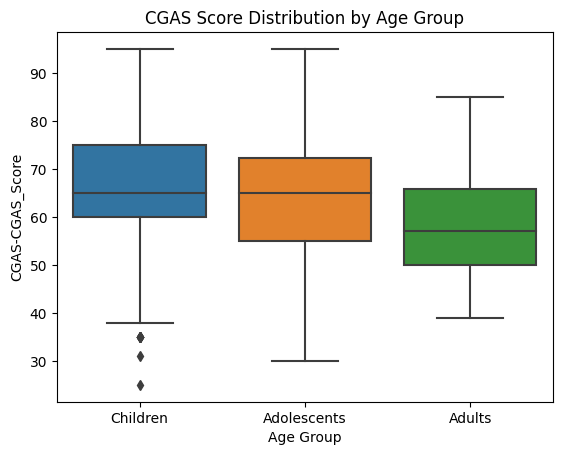

In [23]:
sns.boxplot(data=train, x='Age Group', y='CGAS-CGAS_Score')
plt.title("CGAS Score Distribution by Age Group")
plt.show()

There shouldn't be data for adults. As definition: Children's Global Assessment Scale - Numeric scale used by mental health clinicians to rate the general functioning of youths under the age of 18. Not sure how to handle that so we will just leave it there

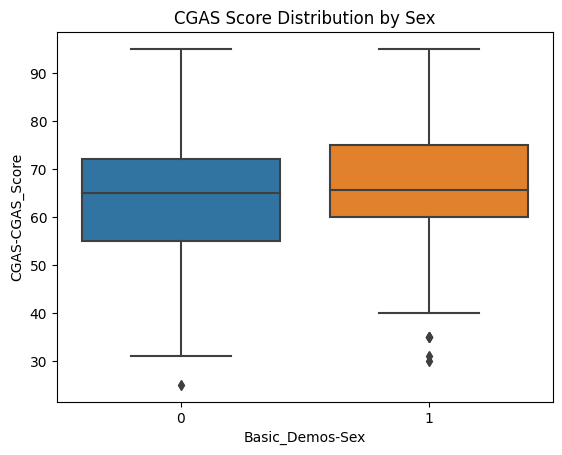

In [24]:
sns.boxplot(data=train, x='Basic_Demos-Sex', y='CGAS-CGAS_Score')
plt.title("CGAS Score Distribution by Sex")
plt.show()

In [25]:
age_group_cgas_stats = train.groupby('Age Group')['CGAS-CGAS_Score'].describe()
age_group_cgas_stats

,count,mean,std,min,25%,50%,75%,max
Age Group,,,,,,,,
Children,1782.0,65.457912,11.644084,25.0,60.0,65.0,75.00,95.0
Adolescents,516.0,64.488372,12.262100,30.0,55.0,65.0,72.25,95.0
Adults,30.0,57.866667,11.834297,39.0,50.0,57.0,65.75,85.0


- The CGAS score distribution differs between the adults group and the children/adolescents groups. However, the adults group has very few samples, and the CGAS test was not designed for adults. Therefore, this information is not usable.
- The CGAS score distribution is similar in the children and adolescents groups.

=> Conclusion: Age cannot be used to predict the CGAS score.

In [26]:
sex_cgas_stats = train.groupby('Basic_Demos-Sex')['CGAS-CGAS_Score'].describe()
sex_cgas_stats

,count,mean,std,min,25%,50%,75%,max
Basic_Demos-Sex,,,,,,,,
0,1494.0,64.254351,11.417116,25.0,55.0,65.0,72.0,95.0
1,834.0,66.741007,12.349262,30.0,60.0,65.5,75.0,95.0


The CGAS distribution is similar for both males and females.

Conclusion: Sex cannot be used to predict the CGAS score.

### Final conclusions: Should not touch the CGAS score yet since the relationship with other columns seems unclear

Relationship with PCIAT Total:

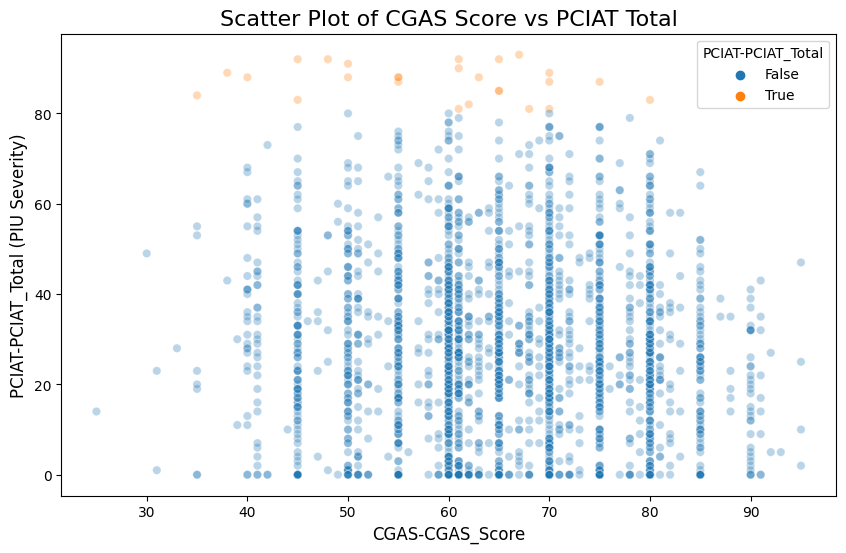

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

valid_data = train.dropna(subset=['CGAS-CGAS_Score', 'PCIAT-PCIAT_Total'])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=valid_data, 
    x='CGAS-CGAS_Score', 
    y='PCIAT-PCIAT_Total',
    hue=valid_data['PCIAT-PCIAT_Total'] > 80,  # PCIAT severe group
    alpha=0.3
)

plt.title("Scatter Plot of CGAS Score vs PCIAT Total", fontsize=16)
plt.xlabel("CGAS-CGAS_Score", fontsize=12)
plt.ylabel("PCIAT-PCIAT_Total (PIU Severity)", fontsize=12)

plt.show()

There are no participants with the highest SII scores (3 or severely problematic internet use) who have good CGAS scores (81-100).
=> Create a weighted function that focuses on the CGAS > 80 group (since this group does not have severe PIU). Use an inverse sigmoid function to assign higher weights to CGAS > 80.

In [28]:
def sigmoid_weight_cgas_high(cgas, a=0.2, b=80):
    return 1 / (1 + np.exp(-a * (cgas - b)))

# Add below
# train['CGAS_Weight'] = train['CGAS-CGAS_Score'].apply(sigmoid_weight_cgas_high)

The CGAS score column will be weighted with this information.

## Physical Measures

In [29]:
physical_columns = [
 'Physical-BMI',
 'Physical-Height',
 'Physical-Weight',
 'Physical-Waist_Circumference',
 'Physical-Diastolic_BP',
 'Physical-HeartRate',
 'Physical-Systolic_BP'
]

wh_cols = [
    'Physical-BMI', 'Physical-Height',
    'Physical-Weight', 'Physical-Waist_Circumference'
]

heart_cols = [
 'Physical-Diastolic_BP',
 'Physical-HeartRate',
 'Physical-Systolic_BP'
]

calculate_stats(train, wh_cols)

,count,mean,std,min,25%,50%,75%,max,missing
Physical-BMI,2513.0,19.131766,4.914565,0.0,15.780022,17.823815,21.173921,46.102914,206
Physical-Height,2516.0,55.885688,7.389588,36.0,50.000000,55.000000,61.637500,78.500000,203
Physical-Weight,2557.0,87.859378,43.356403,0.0,57.200000,75.800000,111.400000,315.000000,162
Physical-Waist_Circumference,480.0,26.631250,5.225146,19.0,23.000000,26.000000,29.000000,50.000000,2239


In [30]:
(train[wh_cols] == 0).sum()

Physical-BMI                     7
Physical-Height                  0
Physical-Weight                 51
Physical-Waist_Circumference     0
dtype: int64

Filter zero values

In [31]:
train[wh_cols] = train[wh_cols].replace(0, np.nan)
test[wh_cols] = test[wh_cols].replace(0, np.nan)
calculate_stats(train, wh_cols)

,count,mean,std,min,25%,50%,75%,max,missing
Physical-BMI,2506.0,19.185206,4.816095,8.522436,15.799058,17.842121,21.206149,46.102914,213
Physical-Height,2516.0,55.885688,7.389588,36.000000,50.000000,55.000000,61.637500,78.500000,203
Physical-Weight,2506.0,89.647418,41.924831,32.800000,58.200000,76.800000,112.200000,315.000000,213
Physical-Waist_Circumference,480.0,26.631250,5.225146,19.000000,23.000000,26.000000,29.000000,50.000000,2239


Since other columns can be inferred from weight and height, we will first focus on filling the missing values in the weight and height columns. Once these are complete, we will use them to predict the remaining physical attributes.

Encode physical seasons:

In [32]:
encoded_season_train = pd.get_dummies(train, columns=['Basic_Demos-Enroll_Season'], prefix='Season', drop_first=False)
encoded_season_test = pd.get_dummies(test, columns=['Basic_Demos-Enroll_Season'], prefix='Season', drop_first=False)
train = train.join(encoded_season_train[['Season_Fall', 'Season_Spring', 'Season_Summer', 'Season_Winter']])
test = test.join(encoded_season_test[['Season_Fall', 'Season_Spring', 'Season_Summer', 'Season_Winter']])
train.columns

Index(['id', 'Basic_Demos-Enroll_Season', 'Basic_Demos-Age', 'Basic_Demos-Sex',
       'CGAS-Season', 'CGAS-CGAS_Score', 'Physical-Season', 'Physical-BMI',
       'Physical-Height', 'Physical-Weight', 'Physical-Waist_Circumference',
       'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP',
       'Fitness_Endurance-Season', 'Fitness_Endurance-Max_Stage',
       'Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec',
       'FGC-Season', 'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND',
       'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'FGC-FGC_PU',
       'FGC-FGC_PU_Zone', 'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR',
       'FGC-FGC_SRR_Zone', 'FGC-FGC_TL', 'FGC-FGC_TL_Zone', 'BIA-Season',
       'BIA-BIA_Activity_Level_num', 'BIA-BIA_BMC', 'BIA-BIA_BMI',
       'BIA-BIA_BMR', 'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM',
       'BIA-BIA_FFMI', 'BIA-BIA_FMI', 'BIA-BIA_Fat', 'BIA-BIA_Frame_num',
       'BIA-BIA_ICW', 'BIA-BIA_LDM', 'BIA-BIA_LST'

Check the relationship between enroll season and w, h

In [33]:
train.groupby('Basic_Demos-Enroll_Season')[['Physical-Weight', 'Physical-Height']].mean()

,Physical-Weight,Physical-Height
Basic_Demos-Enroll_Season,,
Fall,88.344491,55.502040
Spring,87.942814,55.812538
Summer,90.484020,56.010065
Winter,92.070618,56.250434


In [34]:
train.groupby(['Basic_Demos-Enroll_Season', 'Basic_Demos-Sex'])[['Physical-Weight', 'Physical-Height']].mean()

Physical-Weight  Physical-Height
Basic_Demos-Enroll_Season Basic_Demos-Sex                                  
Fall                      0                      87.211184        55.427422
                          1                      90.429778        55.638458
Spring                    0                      88.242691        56.150742
                          1                      87.380870        55.181515
Summer                    0                      92.000529        56.250316
                          1                      87.980786        55.618240
Winter                    0                      92.120366        56.166554
                          1                      91.982407        56.399167

- Weight:
For each season, females tend to have lower or similar weight compared to males.
Example:
Fall: 87.21 (female) vs. 90.43 (male)
Winter: 92.12 (female) ~ 91.98 (male)
Weight tends to be higher in Summer and Winter and lower in Fall and Spring, but the difference between seasons is minimal (1–5 kg).

- Height:
Males are consistently taller than females across all seasons, but the difference is relatively small (0.1–1 cm).
Example:
Spring: 55.18 (female) vs. 56.15 (male)
Winter: 56.16 (female) vs. 56.39 (male)
Seasonal variation in height is negligible, with a maximum difference of around 1 cm between seasons.

=> Conclusion:
Weight: There are slight differences across seasons and genders, particularly with higher weights in Summer and Winter. However, these variations are minor and could be influenced by other factors like age or lifestyle.
Height: Seasonal effects on height are almost insignificant, as the average difference between seasons is less than 1 cm.

However there is very little data so we will still be using all 3 three columns season, age and sex to predict missing values for w and h

Convert to cm and kg

In [35]:
lbs_to_kg = 0.453592
inches_to_cm = 2.54

def process_physical_BMI(df):
    df['Physical-Weight'] = df['Physical-Weight'] * lbs_to_kg
    df['Physical-Height'] = df['Physical-Height'] * inches_to_cm
    df['Physical-Waist_Circumference'] = df['Physical-Waist_Circumference'] * inches_to_cm
    
    df['Physical-BMI'] = np.where(
        df['Physical-Weight'].notna() & df['Physical-Height'].notna(),
        df['Physical-Weight'] / ((df['Physical-Height'] / 100) ** 2),
        np.nan
    )
    
    return df

train = process_physical_BMI(train)
test = process_physical_BMI(test)

calculate_stats(train, wh_cols)

,count,mean,std,min,25%,50%,75%,max,missing
Physical-BMI,2506.0,19.187090,4.816567,8.523273,15.800609,17.843872,21.208231,46.107439,213
Physical-Height,2516.0,141.949647,18.769553,91.440000,127.000000,139.700000,156.559250,199.390000,203
Physical-Weight,2506.0,40.663352,19.016768,14.877818,26.399054,34.835866,50.893022,142.881480,213
Physical-Waist_Circumference,480.0,67.643375,13.271871,48.260000,58.420000,66.040000,73.660000,127.000000,2239


Fill missing data for w and h using knn. We will only use Season_Fall and Season_Winter, as these are the two season columns with the highest height and weight differences among participants. This is to avoid potential bias from using seasons with smaller differences in weight and height, which could lead to less accurate predictions.

In [36]:
from sklearn.impute import KNNImputer

# Chọn 2 mùa có chiều cao cân nặng chênh nhau nhiều nhất
imputer = KNNImputer(n_neighbors=10)

selected_features = ['Basic_Demos-Age', 'Season_Fall', 'Season_Winter', 'Basic_Demos-Sex', 'Physical-Weight', 'Physical-Height']

imputed_data = imputer.fit_transform(train[selected_features])
train_imputed = pd.DataFrame(imputed_data, columns=selected_features)
train = train.drop(columns=selected_features).reset_index()

imputed_test_data = imputer.transform(test[selected_features])
test_imputed = pd.DataFrame(imputed_test_data, columns=selected_features)
test = test.drop(columns=selected_features).reset_index()

train = pd.concat([train, train_imputed], axis=1)
test = pd.concat([test, test_imputed], axis=1)

calculate_stats(train, ['Physical-Weight', 'Physical-Height'])

,count,mean,std,min,25%,50%,75%,max,missing
Physical-Weight,2719.0,40.718895,18.806414,14.877818,26.67121,34.745147,50.847663,142.88148,0
Physical-Height,2719.0,141.913875,18.671087,91.440000,127.13970,139.700000,156.210000,199.39000,0


Recalculate BMI from w and h

In [37]:
train['Physical-BMI'] = train.apply(
    lambda row: row['Physical-Weight'] / (row['Physical-Height'] / 100) ** 2 
    if pd.isnull(row['Physical-BMI']) else row['Physical-BMI'], axis=1
)
test['Physical-BMI'] = test.apply(
    lambda row: row['Physical-Weight'] / (row['Physical-Height'] / 100) ** 2 
    if pd.isnull(row['Physical-BMI']) else row['Physical-BMI'], axis=1
)
calculate_stats(train, ['Physical-BMI'])

,count,mean,std,min,25%,50%,75%,max,missing
Physical-BMI,,,,,,,,,
Physical-BMI,2719.0,19.22914,4.693758,8.523273,15.954858,17.957047,21.289471,46.107439,0


Compare with the BIA-BIA_BMI column, which is also the BMI index measured in the same year.

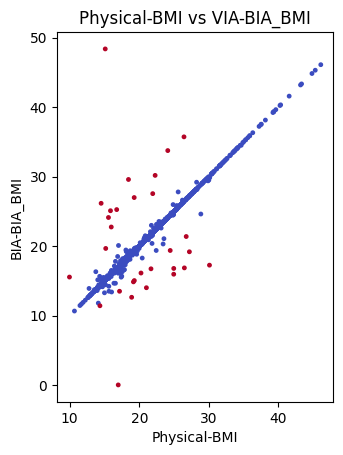

In [38]:
bmi_ratio = train['Physical-BMI'] / train['BIA-BIA_BMI']
color = (bmi_ratio < 0.8) | (bmi_ratio > 1.2)  # red if difference > 30%

plt.scatter(
    train['Physical-BMI'],
    train['BIA-BIA_BMI'],
    s=6,
    c=color,
    cmap='coolwarm'
)
plt.gca().set_aspect('equal')
plt.xlabel('Physical-BMI')
plt.ylabel('BIA-BIA_BMI')
plt.title('Physical-BMI vs VIA-BIA_BMI')
plt.show()

The red points indicate that one of the two columns is incorrect, as BMI does not change significantly within a year. Replace the BIA-BMI of these points with the newly calculated Physical-BMI.

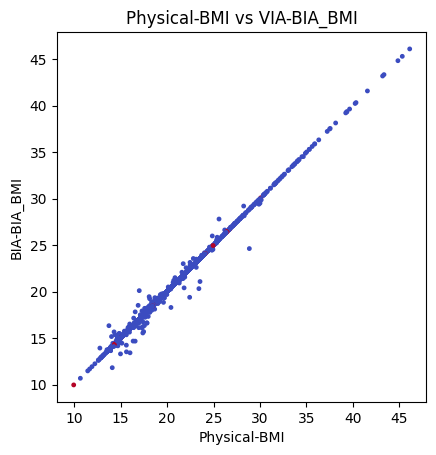

In [39]:
train.loc[color, 'BIA-BIA_BMI'] = train.loc[color, 'Physical-BMI']
plt.scatter(
    train['Physical-BMI'],
    train['BIA-BIA_BMI'],
    s=6,
    c=color,
    cmap='coolwarm'
)
plt.gca().set_aspect('equal')
plt.xlabel('Physical-BMI')
plt.ylabel('BIA-BIA_BMI')
plt.title('Physical-BMI vs VIA-BIA_BMI')
plt.show()

Waist is important because sitting a lot leads to a bigger belly. :))
There are many missing values for Waist (2239), so KNN will not be used.
Waist Circumference (cm) = a × BMI + b × Height (cm) + c
=> Using regression model

In [40]:
waist_data = train.dropna(subset=['Physical-Waist_Circumference'])

X = waist_data[['Physical-BMI', 'Physical-Weight']]
y = waist_data['Physical-Waist_Circumference']

from sklearn.linear_model import LinearRegression
waist_model = LinearRegression()
waist_model.fit(X, y)

LinearRegression()

Dự đoán các giá trị bị thiếu

In [41]:
missing_waist = train['Physical-Waist_Circumference'].isnull()
train.loc[missing_waist, 'Physical-Waist_Circumference'] = waist_model.predict(
    train.loc[missing_waist, ['Physical-BMI', 'Physical-Weight']]
)

missing_waist_test = test['Physical-Waist_Circumference'].isnull()
test.loc[missing_waist_test, 'Physical-Waist_Circumference'] = waist_model.predict(
    test.loc[missing_waist_test, ['Physical-BMI', 'Physical-Weight']]
)

calculate_stats(train, wh_cols)

,count,mean,std,min,25%,50%,75%,max,missing
Physical-BMI,2719.0,19.229140,4.693758,8.523273,15.954858,17.957047,21.289471,46.107439,0
Physical-Height,2719.0,141.913875,18.671087,91.440000,127.139700,139.700000,156.210000,199.390000,0
Physical-Weight,2719.0,40.718895,18.806414,14.877818,26.671210,34.745147,50.847663,142.881480,0
Physical-Waist_Circumference,2719.0,67.948114,12.081490,47.385325,59.050320,64.653554,73.660746,133.642999,0


### Blood Pressure và Heart Rate

In [42]:
bp_hr_cols = [
    'Physical-Diastolic_BP', 'Physical-Systolic_BP',
    'Physical-HeartRate'
]

In [43]:
(train[bp_hr_cols] < 50).sum()

Physical-Diastolic_BP    77
Physical-Systolic_BP      1
Physical-HeartRate       10
dtype: int64

In [44]:
train[train['Physical-Systolic_BP'] <= train['Physical-Diastolic_BP']][bp_hr_cols]

,Physical-Diastolic_BP,Physical-Systolic_BP,Physical-HeartRate
783,179.0,139.0,103.0
1292,117.0,114.0,114.0


Filter rows where heartrate < 50 and systolic < diastolic.

In [45]:
train[bp_hr_cols] = train[bp_hr_cols].replace(0, np.nan)
train.loc[train['Physical-Systolic_BP'] <= train['Physical-Diastolic_BP'], bp_hr_cols] = np.nan

Not sure what to do with this data since it can be varied so we will leave it there

## Sleep Disturbance Scale

We expect this data to be important since us ourselves experience severe sleep disturbance from this course 

In [46]:
SDS_columns = ['SDS-Season', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T']

SDS_number_columns = ['SDS-SDS_Total_Raw', 'SDS-SDS_Total_T']

In [47]:
calculate_stats(train, 'SDS-Season')

,count (%)
SDS-Season,
NaN,206 (7.58%)
Fall,602 (22.14%)
Summer,598 (21.99%)
Winter,625 (22.99%)
Spring,688 (25.3%)


In [48]:
calculate_stats(train, SDS_number_columns)

,count,mean,std,min,25%,50%,75%,max,missing
SDS-SDS_Total_Raw,2513.0,40.987266,10.235631,17.0,33.0,39.0,46.0,96.0,206
SDS-SDS_Total_T,2511.0,57.658702,13.047179,38.0,47.0,55.0,64.0,100.0,208


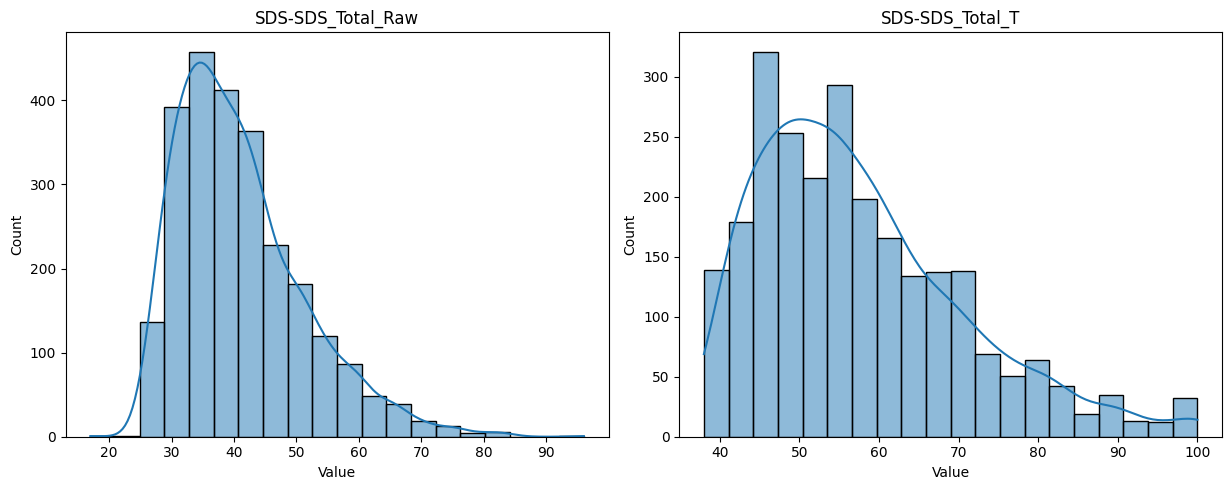

In [49]:
plt.figure(figsize=(18, 5))

# SDS-SDS_Total_Raw
plt.subplot(1, 3, 2)
sns.histplot(train['SDS-SDS_Total_Raw'].dropna(), bins=20, kde=True)
plt.title('SDS-SDS_Total_Raw')
plt.xlabel('Value')

# SDS-SDS_Total_T
plt.subplot(1, 3, 3)
sns.histplot(train['SDS-SDS_Total_T'].dropna(), bins=20, kde=True)
plt.title('SDS-SDS_Total_T')
plt.xlabel('Value')

plt.tight_layout()
plt.show()

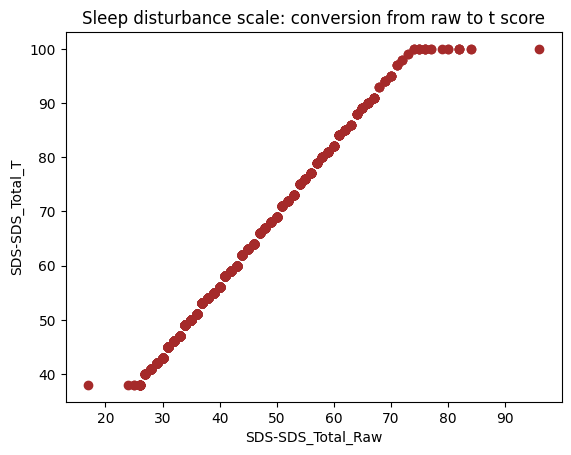

In [50]:
plt.title('Sleep disturbance scale: conversion from raw to t score')
plt.scatter(train['SDS-SDS_Total_Raw'],
            train['SDS-SDS_Total_T'],
            color='brown')
plt.xlabel('SDS-SDS_Total_Raw')
plt.ylabel('SDS-SDS_Total_T')
plt.show()

There are many SDS_Total_Raw values rounded to the same value as SDS_Total_T. Since the SDS_Total_Raw column contains more information than SDS_Total_T, drop SDS_Total_T should be fine.

In [51]:
train = train.drop(columns=['SDS-SDS_Total_T'])
test = test.drop(columns=['SDS-SDS_Total_T'])

Check extreme sleep disturbance cases

In [52]:
cols=['Basic_Demos-Age', 'Age Group', 'SDS-SDS_Total_Raw', 'PCIAT-PCIAT_Total']
train[train['SDS-SDS_Total_Raw'] > 70][cols]

,Basic_Demos-Age,Age Group,SDS-SDS_Total_Raw,PCIAT-PCIAT_Total
29,12.0,Children,82.0,46.0
174,8.0,Children,84.0,49.0
276,10.0,Children,71.0,74.0
355,8.0,Children,75.0,35.0
433,7.0,Children,71.0,29.0
440,10.0,Children,77.0,23.0
511,8.0,Children,73.0,0.0
541,10.0,Children,74.0,20.0
585,5.0,Children,72.0,32.0
664,6.0,Children,71.0,27.0


In [53]:
train[train['SDS-SDS_Total_Raw'] > 70].groupby('Age Group').size()

Age Group
Children       28
Adolescents     4
Adults          0
dtype: int64

There are 28 children experiencing severe sleep disturbance, which might not be true since they are... children? We will remove these values (capping technique to avoid extreme values)

In [54]:
train['SDS-SDS_Total_Raw'] = train.apply(
    lambda row: np.nan if row['Age Group'] == 'Children' and row['SDS-SDS_Total_Raw'] > 70 else row['SDS-SDS_Total_Raw'], 
    axis=1
)
train[train['SDS-SDS_Total_Raw'] > 70][cols]

,Basic_Demos-Age,Age Group,SDS-SDS_Total_Raw,PCIAT-PCIAT_Total
732,18.0,Adolescents,75.0,92.0
1332,15.0,Adolescents,77.0,60.0
2077,17.0,Adolescents,79.0,53.0
2185,14.0,Adolescents,74.0,36.0


Check the relationship with PIU

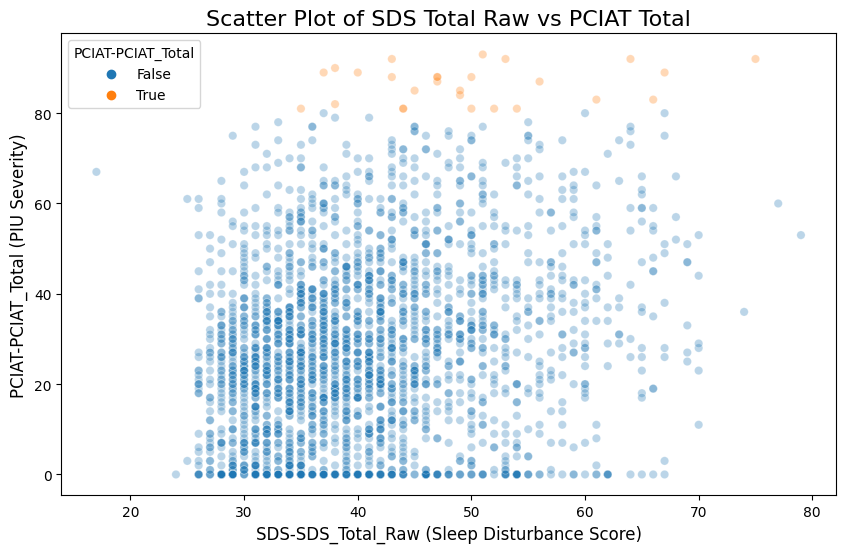

In [55]:
valid_data = train.dropna(subset=['SDS-SDS_Total_Raw', 'PCIAT-PCIAT_Total'])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=valid_data, 
    x='SDS-SDS_Total_Raw', 
    y='PCIAT-PCIAT_Total',
    hue=valid_data['PCIAT-PCIAT_Total'] > 80,  # PCIAT severe group
    alpha=0.3
)

plt.title("Scatter Plot of SDS Total Raw vs PCIAT Total", fontsize=16)
plt.xlabel("SDS-SDS_Total_Raw (Sleep Disturbance Score)", fontsize=12)
plt.ylabel("PCIAT-PCIAT_Total (PIU Severity)", fontsize=12)

plt.show()

- Not so clear linear trend

- The data is concentrated in the lower left corner. This indicates that most of the samples have low SDS and PCIAT values, meaning the majority of survey participants do not have severe sleep disturbances or heavy Internet addiction.

- When SDS < 35, there is no PCIAT > 80 (SII = 3). This suggests that individuals with low sleep disturbances generally do not have severe Internet addiction. This reinforces the relationship between sleep disturbances and Internet addiction: sleep disturbances could be a predictor of severe Internet addiction.

=> Conclusion: Add a new column for SDS_Weight.

SDS-Season

In [56]:
season_stats = train.groupby('SDS-Season')['SDS-SDS_Total_Raw'].agg(['mean', 'median'])
season_stats

,mean,median
SDS-Season,,
Fall,40.350168,38.0
Spring,40.454412,39.0
Summer,40.683502,39.0
Winter,40.852512,40.0


SDS is higher in winter

Fill SDS-Season with the ratio of each season's occurrence.

In [57]:
season_counts = train['SDS-Season'].value_counts(normalize=True)

train['SDS-Season'] = train['SDS-Season'].apply(
    lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x
)
test['SDS-Season'] = test['SDS-Season'].apply(
    lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x
)

calculate_stats(train, 'SDS-Season')

,count (%)
SDS-Season,
Summer,641 (23.57%)
Fall,647 (23.8%)
Winter,675 (24.83%)
Spring,756 (27.8%)


Check relationship between Age Sex and SDS score

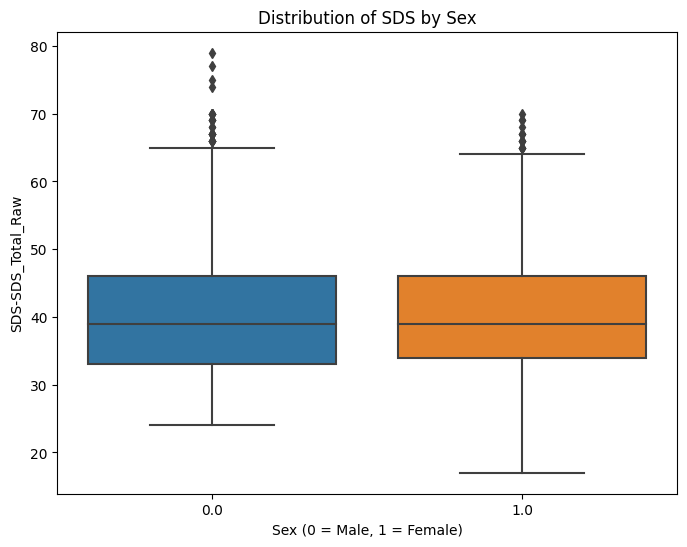

In [58]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Basic_Demos-Sex', y='SDS-SDS_Total_Raw', data=train)
plt.title('Distribution of SDS by Sex')
plt.xlabel('Sex (0 = Male, 1 = Female)')
plt.ylabel('SDS-SDS_Total_Raw')
plt.show()

It looks same to us...

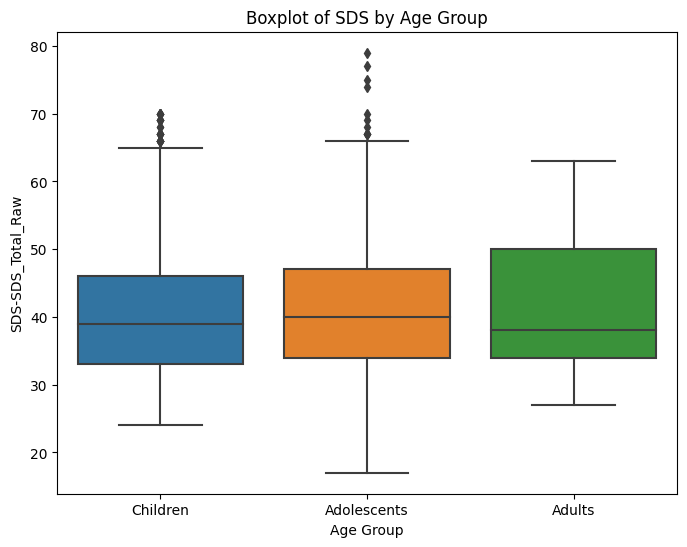

In [59]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Age Group', y='SDS-SDS_Total_Raw', data=train)
plt.title('Boxplot of SDS by Age Group')
plt.xlabel('Age Group')
plt.ylabel('SDS-SDS_Total_Raw')
plt.show()

- Adults have no outliers with high SDS, but this age group has very little data.
- Adolescents have the highest median SDS, which makes sense.


=> Use Age and SDS-Season to predict the SDS score

Encode season columns

In [60]:
encoded_season_df = pd.get_dummies(train, columns=['SDS-Season'], prefix='SDS-Season', drop_first=False)
train = train.join(encoded_season_df[['SDS-Season_Fall', 'SDS-Season_Spring', 'SDS-Season_Summer', 'SDS-Season_Winter']])

encoded_season_df = pd.get_dummies(test, columns=['SDS-Season'], prefix='SDS-Season', drop_first=False)
test = test.join(encoded_season_df[['SDS-Season_Fall', 'SDS-Season_Spring', 'SDS-Season_Summer', 'SDS-Season_Winter']])

train.columns

Index(['index', 'id', 'Basic_Demos-Enroll_Season', 'CGAS-Season',
       'CGAS-CGAS_Score', 'Physical-Season', 'Physical-BMI',
       'Physical-Waist_Circumference', 'Physical-Diastolic_BP',
       'Physical-HeartRate', 'Physical-Systolic_BP',
       'Fitness_Endurance-Season', 'Fitness_Endurance-Max_Stage',
       'Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec',
       'FGC-Season', 'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND',
       'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'FGC-FGC_PU',
       'FGC-FGC_PU_Zone', 'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR',
       'FGC-FGC_SRR_Zone', 'FGC-FGC_TL', 'FGC-FGC_TL_Zone', 'BIA-Season',
       'BIA-BIA_Activity_Level_num', 'BIA-BIA_BMC', 'BIA-BIA_BMI',
       'BIA-BIA_BMR', 'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM',
       'BIA-BIA_FFMI', 'BIA-BIA_FMI', 'BIA-BIA_Fat', 'BIA-BIA_Frame_num',
       'BIA-BIA_ICW', 'BIA-BIA_LDM', 'BIA-BIA_LST', 'BIA-BIA_SMM',
       'BIA-BIA_TBW', 'PAQ_A-Season', 'PAQ_A-PAQ_A

Fill missing SDS-SDS_Total_Raw values with Age SDS-season by KNN

In [61]:
X_train_SDS_Score = train[['Basic_Demos-Age', 'SDS-Season_Fall', 'SDS-Season_Spring', 'SDS-Season_Winter']]

y_train_SDS_Score = train['SDS-SDS_Total_Raw']

In [62]:
sds_imputer = KNNImputer(n_neighbors=7)

data_with_sds = pd.concat([X_train_SDS_Score, y_train_SDS_Score], axis=1)

filled_data = sds_imputer.fit_transform(data_with_sds)

columns = data_with_sds.columns.tolist()
filled_df = pd.DataFrame(filled_data, columns=columns)

train['SDS-SDS_Total_Raw'] = filled_df['SDS-SDS_Total_Raw']
calculate_stats(train, ['SDS-SDS_Total_Raw'])

,count,mean,std,min,25%,50%,75%,max,missing
SDS-SDS_Total_Raw,,,,,,,,,
SDS-SDS_Total_Raw,2719.0,40.598487,9.151488,17.0,34.0,39.142857,45.0,79.0,0


Fill test data with trained imputer

In [63]:
X_test_SDS_Score = test[['Basic_Demos-Age', 'SDS-Season_Fall', 'SDS-Season_Spring', 'SDS-Season_Winter']]
y_test_SDS_Score = test['SDS-SDS_Total_Raw']

In [64]:
data_test_with_sds = pd.concat([X_test_SDS_Score, y_test_SDS_Score], axis=1)
filled_test_data = sds_imputer.transform(data_test_with_sds)
filled_test_df = pd.DataFrame(filled_test_data, columns=data_test_with_sds.columns)
test['SDS-SDS_Total_Raw'] = filled_test_df['SDS-SDS_Total_Raw']

Add SDS_Weight

In [65]:
def sigmoid_weight(sds, a=0.1, b=35):
    return 1 / (1 + np.exp(a * (sds - b)))

train['SDS_Weight'] = train['SDS-SDS_Total_Raw'].apply(sigmoid_weight)
test['SDS_Weight'] = test['SDS-SDS_Total_Raw'].apply(sigmoid_weight)
train[['SDS_Weight', 'SDS-SDS_Total_Raw']]

,SDS_Weight,SDS-SDS_Total_Raw
0,0.354344,41.0
1,0.249740,46.0
2,0.425557,38.0
3,0.598688,31.0
4,0.377541,40.0
...,...,...
2714,0.354344,41.0
2715,0.214165,48.0
2716,0.500000,35.0
2717,0.109097,56.0


## Internet Use

This should be important too

In [66]:
calculate_stats(train, 'PreInt_EduHx-Season')

,count (%)
PreInt_EduHx-Season,
Fall,683 (25.12%)
Summer,649 (23.87%)
Winter,648 (23.83%)
Spring,722 (26.55%)
NaN,17 (0.63%)


In [67]:
calculate_stats(train, ['PreInt_EduHx-computerinternet_hoursday'])

,count,mean,std,min,25%,50%,75%,max,missing
PreInt_EduHx-computerinternet_hoursday,,,,,,,,,
PreInt_EduHx-computerinternet_hoursday,2637.0,1.011756,1.080001,0.0,0.0,1.0,2.0,3.0,82


Relationshiop with age and sex

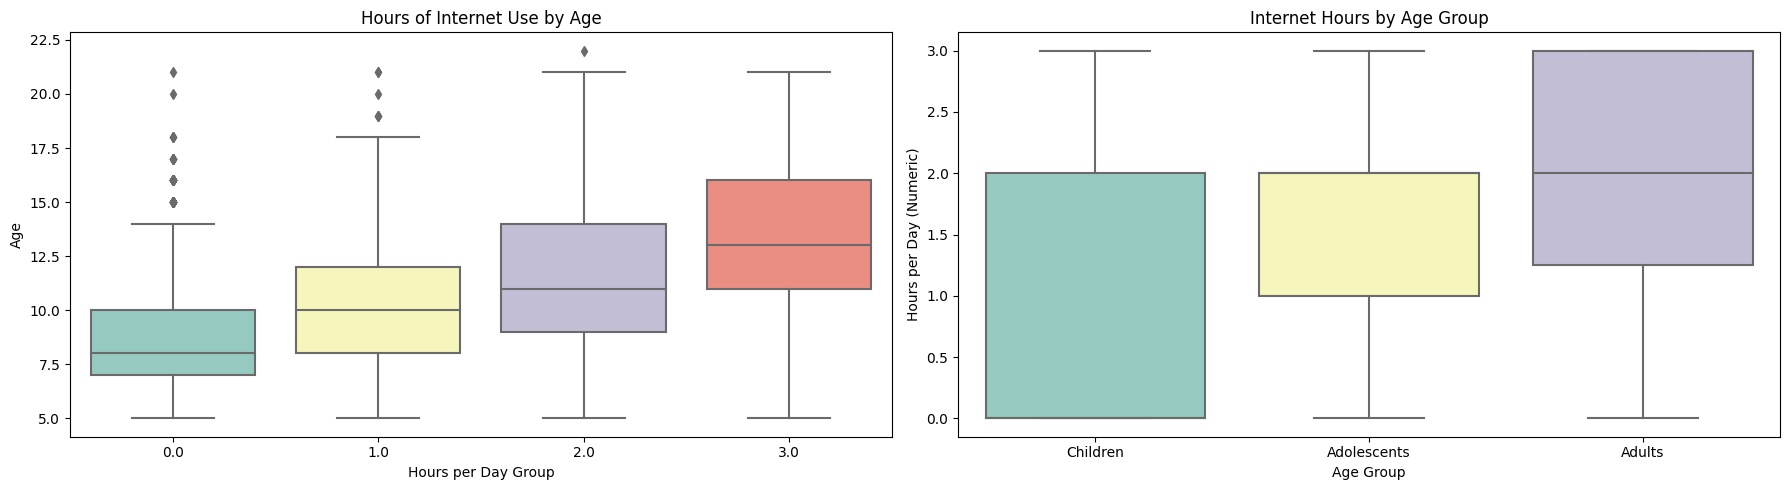

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Hours of Internet Use by Age
sns.boxplot(y=train['Basic_Demos-Age'], x=train['PreInt_EduHx-computerinternet_hoursday'], ax=axes[0], palette="Set3")
axes[0].set_title('Hours of Internet Use by Age')
axes[0].set_ylabel('Age')
axes[0].set_xlabel('Hours per Day Group')

# Hours of Internet Use by Age Group
sns.boxplot(y='PreInt_EduHx-computerinternet_hoursday', x='Age Group', data=train, ax=axes[1], palette="Set3")
axes[1].set_title('Internet Hours by Age Group')
axes[1].set_ylabel('Hours per Day (Numeric)')
axes[1].set_xlabel('Age Group')

plt.tight_layout()
plt.show()

In [69]:
stats = train.groupby(['Basic_Demos-Sex', 'PreInt_EduHx-computerinternet_hoursday']
).size().unstack(fill_value=0)
stats_prop = stats.div(stats.sum(axis=1), axis=0) * 100

stats = stats.astype(str) +' (' + stats_prop.round(1).astype(str) + '%)'
stats

PreInt_EduHx-computerinternet_hoursday,0.0,1.0,2.0,3.0
Basic_Demos-Sex,,,,
0.0,793 (47.1%),224 (13.3%),505 (30.0%),160 (9.5%)
1.0,470 (49.2%),115 (12.0%),271 (28.4%),99 (10.4%)


- Older age leads to more internet use => create a new feature combining age and internet use.
- Sex is not useful

Relationship with sii

In [70]:
stats = train.groupby(
    ['sii', 'PreInt_EduHx-computerinternet_hoursday']
).size().unstack(fill_value=0)
stats_prop = stats.div(stats.sum(axis=1), axis=0) * 100

stats = stats.astype(str) +' (' + stats_prop.round(1).astype(str) + '%)'
stats

PreInt_EduHx-computerinternet_hoursday,0.0,1.0,2.0,3.0
sii,,,,
0.0,933 (60.8%),160 (10.4%),366 (23.9%),75 (4.9%)
1.0,247 (34.9%),123 (17.4%),251 (35.5%),86 (12.2%)
2.0,78 (21.5%),54 (14.9%),147 (40.6%),83 (22.9%)
3.0,5 (14.7%),2 (5.9%),12 (35.3%),15 (44.1%)


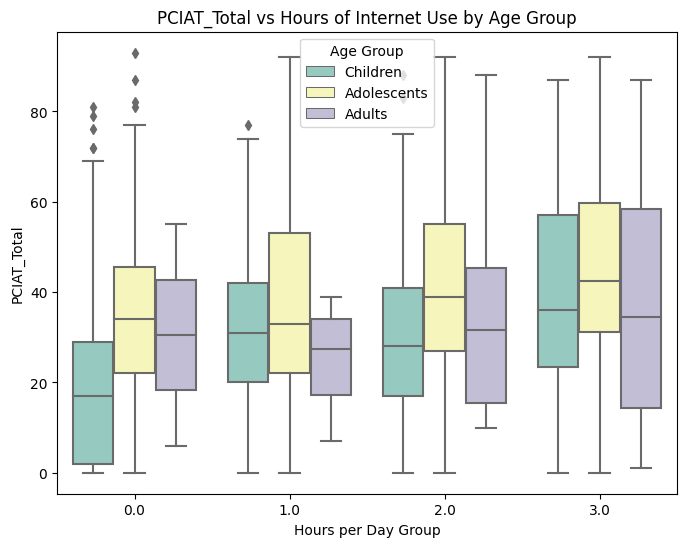

In [71]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='PreInt_EduHx-computerinternet_hoursday', y='PCIAT-PCIAT_Total',
    data=train,
    hue='Age Group', palette="Set3"
)
plt.title('PCIAT_Total vs Hours of Internet Use by Age Group')
plt.ylabel('PCIAT_Total')
plt.xlabel('Hours per Day Group')
plt.show()

- Many people use the internet for <1 hour/day but still have SII = 2 or 3
=> Check other indicators to see if there are any factors contributing to PIU that are unrelated to internet use.
- Many people use the internet for >3 hours/day but still have SII = 0 or 1
Check these two groups.

High internet use low sii group:

In [72]:
high_sii_high_internet = train[(train['sii'] >= 2) & (train['PreInt_EduHx-computerinternet_hoursday'] >= 2)]
low_sii_high_internet = train[(train['sii'] < 2) & (train['PreInt_EduHx-computerinternet_hoursday'] >= 2)]

In [73]:
high_sii_means = [
    high_sii_high_internet['Basic_Demos-Age'].mean(),
    high_sii_high_internet['Basic_Demos-Sex'].mean(),
    high_sii_high_internet['Physical-Weight'].mean(),
    high_sii_high_internet['Physical-Height'].mean(),
    high_sii_high_internet['SDS-SDS_Total_Raw'].mean(),
    high_sii_high_internet['CGAS-CGAS_Score'].mean(),
    len(high_sii_high_internet),
]
low_sii_means = [
    low_sii_high_internet['Basic_Demos-Age'].mean(),
    low_sii_high_internet['Basic_Demos-Sex'].mean(),
    low_sii_high_internet['Physical-Weight'].mean(),
    low_sii_high_internet['Physical-Height'].mean(),
    low_sii_high_internet['SDS-SDS_Total_Raw'].mean(),
    low_sii_high_internet['CGAS-CGAS_Score'].mean(),
    len(low_sii_high_internet),
]

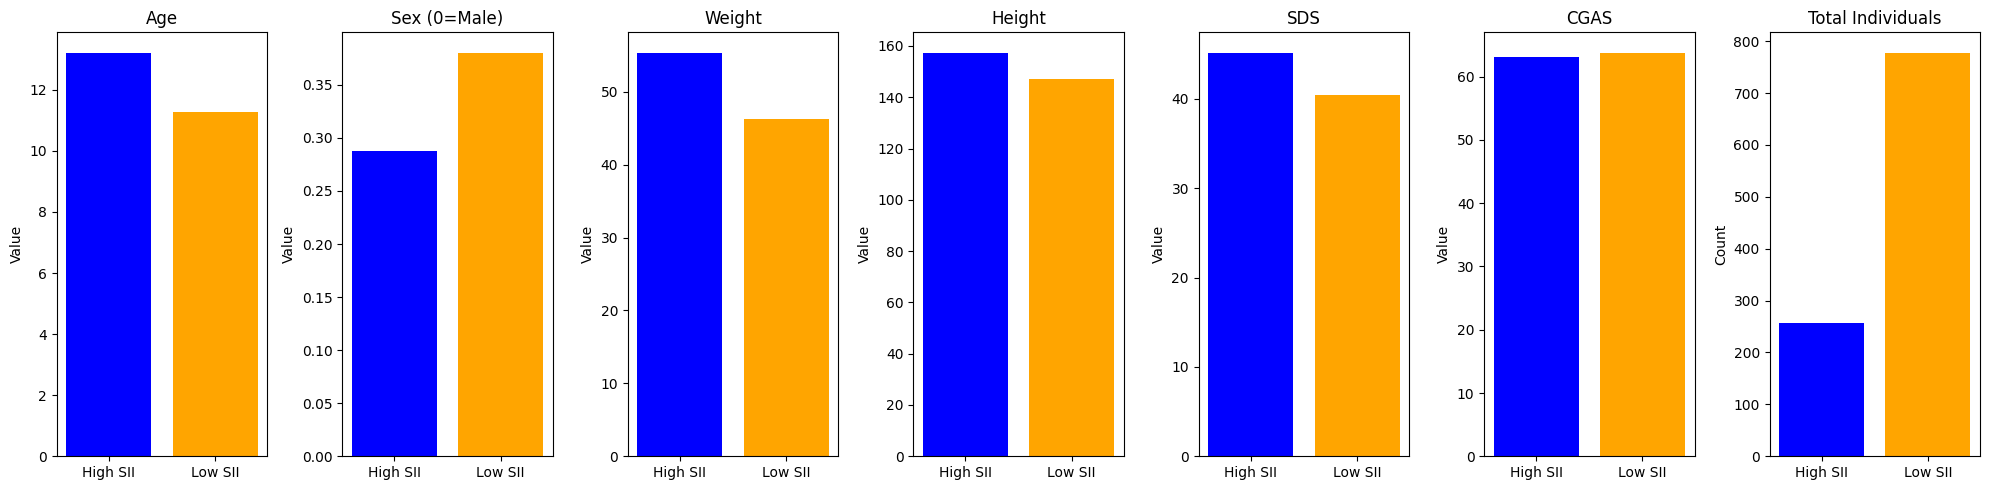

In [74]:
labels = ['Age', 'Sex (0=Male)', 'Weight', 'Height', 'SDS', 'CGAS', 'Total Individuals']

fig, axes = plt.subplots(1, 7, figsize=(20, 5), sharey=False)

for i, ax in enumerate(axes):
    ax.bar(['High SII', 'Low SII'], [high_sii_means[i], low_sii_means[i]], color=['blue', 'orange'])
    ax.set_title(labels[i])
    ax.set_ylabel('Value' if i != 6 else 'Count')

plt.tight_layout()
plt.show()

- There is a large difference in quantity between the groups.
- The high SII group is older, which makes sense => Create a new feature combining age and internet hours.
- Higher w, h, and SDS may just reflect age.
- There is a trend where males have higher SII => Create a new feature combining age and sex (we ran out of time).

Low internet high piu:

In [75]:
high_sii_low_internet = train[(train['sii'] >= 2) & (train['PreInt_EduHx-computerinternet_hoursday'] < 2)]
low_sii_low_internet = train[(train['sii'] < 2) & (train['PreInt_EduHx-computerinternet_hoursday'] < 2)]

In [76]:
high_sii_means = [
    high_sii_low_internet['Basic_Demos-Age'].mean(),
    high_sii_low_internet['Basic_Demos-Sex'].mean(),
    high_sii_low_internet['Physical-Weight'].mean(),
    high_sii_low_internet['Physical-Height'].mean(),
    high_sii_low_internet['SDS-SDS_Total_Raw'].mean(),
    high_sii_low_internet['CGAS-CGAS_Score'].mean(),
    len(high_sii_low_internet)
]
low_sii_means = [
    low_sii_low_internet['Basic_Demos-Age'].mean(),
    low_sii_low_internet['Basic_Demos-Sex'].mean(),
    low_sii_low_internet['Physical-Weight'].mean(),
    low_sii_low_internet['Physical-Height'].mean(),
    low_sii_low_internet['SDS-SDS_Total_Raw'].mean(),
    low_sii_low_internet['CGAS-CGAS_Score'].mean(),
    len(low_sii_low_internet)
]

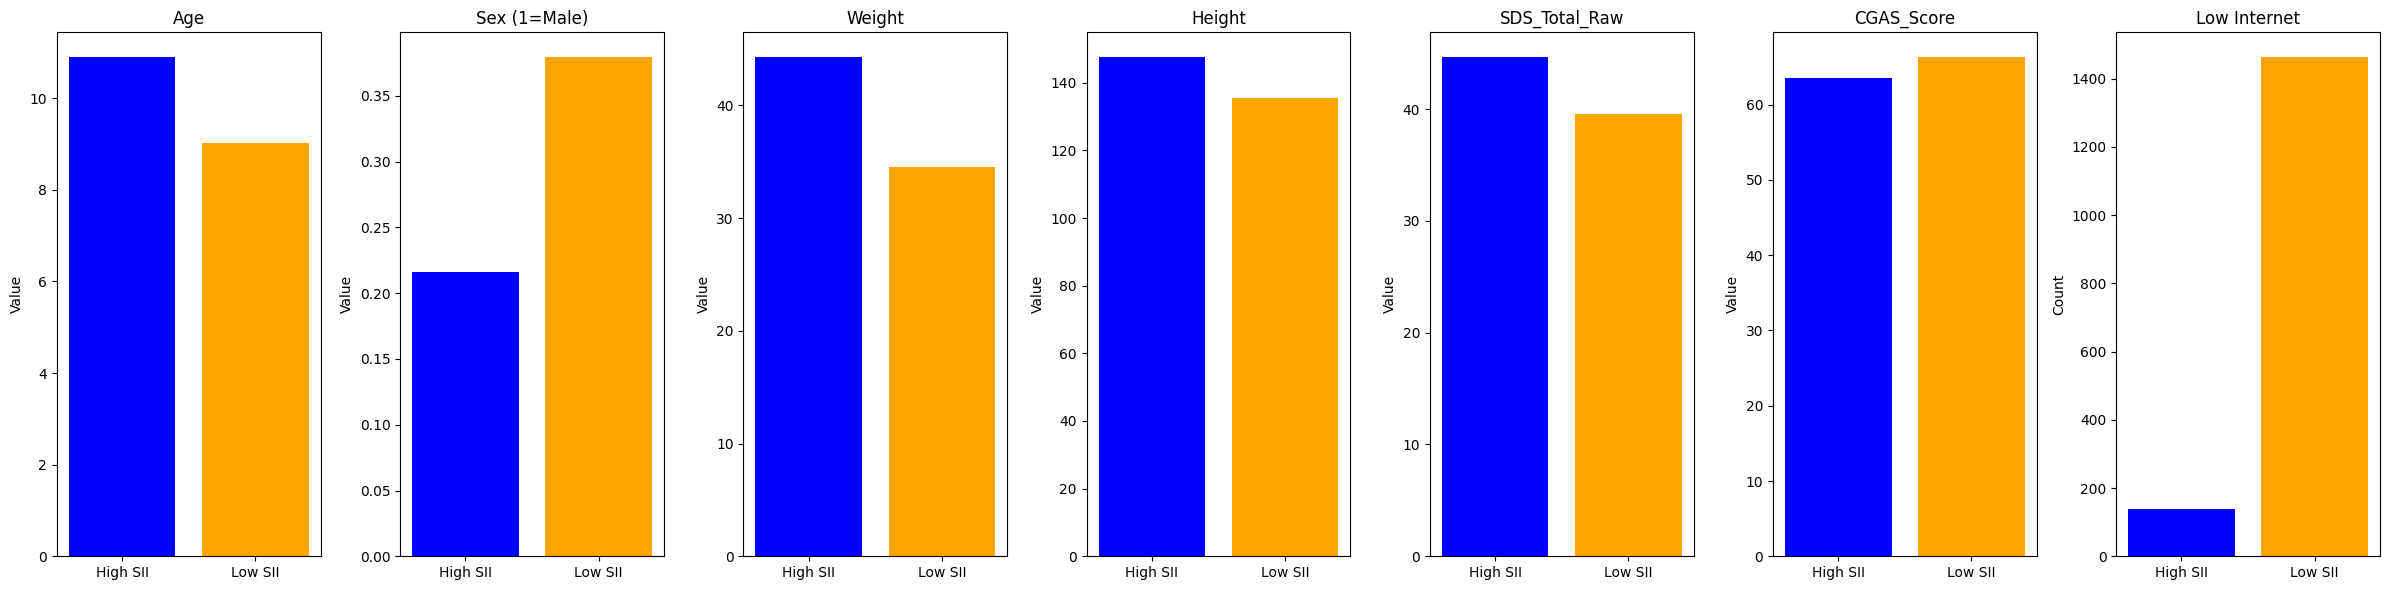

In [77]:
labels = ['Age', 'Sex (1=Male)', 'Weight', 'Height', 'SDS_Total_Raw', 'CGAS_Score', 'Total Individuals']

groups = ['High SII', 'Low SII']
data = [high_sii_means, low_sii_means]

fig, axes = plt.subplots(1, 7, figsize=(24, 6), sharey=False)

for i, ax in enumerate(axes):
    ax.bar(groups, [data[0][i], data[1][i]], color=['blue', 'orange'])
    ax.set_title(labels[i])
    ax.set_ylabel('Value' if i != 6 else 'Count')

plt.title('Low Internet')
plt.tight_layout()
plt.show()

- The number of people with low SII is higher than those with high SII, which makes sense.
- The number of people with high SII is lower than those with high internet use, which makes sense.

Conclusion: In both cases of high SII with low internet use and high SII with high internet use, the majority are male. A feature from sex and internet use might be useful. And of course a feature from age and internet use too

### PreInt_EduHx-Season

Fill missing season cols

In [78]:
season_counts = train['PreInt_EduHx-Season'].value_counts(normalize=True)

train['PreInt_EduHx-Season'] = train['PreInt_EduHx-Season'].apply(lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x)
test['PreInt_EduHx-Season'] = test['PreInt_EduHx-Season'].apply(lambda x: np.random.choice(season_counts.index, p=season_counts.values) if pd.isna(x) else x)

calculate_stats(train, 'PreInt_EduHx-Season')

,count (%)
PreInt_EduHx-Season,
Fall,684 (25.16%)
Summer,654 (24.05%)
Winter,650 (23.91%)
Spring,731 (26.88%)


###  PreInt_EduHx-computerinternet_hoursday

We will be using Logistic Regression to predict internet use hours

In [79]:
features = ['Basic_Demos-Age', 'Basic_Demos-Sex', 'SDS-SDS_Total_Raw', 'PreInt_EduHx-Season']
target = 'PreInt_EduHx-computerinternet_hoursday'

train_data = train[train[target].notna()]

X_train = train_data[features]
y_train = train_data[target]

preprocessor = ColumnTransformer(
    transformers=[
        ('season', OneHotEncoder(), ['PreInt_EduHx-Season']),  # Mùa
        ('num', 'passthrough', ['Basic_Demos-Age', 'Basic_Demos-Sex', 'SDS-SDS_Total_Raw'])  # Các cột số
    ])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, multi_class='ovr'))
])

model.fit(X_train, y_train)

X_missing = train[train[target].isna()][features]
predicted_values = model.predict(X_missing)

train.loc[train[target].isna(), target] = predicted_values

X_missing_test = test[test[target].isna()][features]
predicted_values_test = model.predict(X_missing_test)

test.loc[test[target].isna(), target] = predicted_values_test

calculate_stats(train, ['PreInt_EduHx-computerinternet_hoursday'])

,count,mean,std,min,25%,50%,75%,max,missing
PreInt_EduHx-computerinternet_hoursday,,,,,,,,,
PreInt_EduHx-computerinternet_hoursday,2719.0,1.006988,1.078737,0.0,0.0,1.0,2.0,3.0,0


## PAQ

In [80]:
PAQ_Adolescents_columns = ['PAQ_A-Season', 'PAQ_A-PAQ_A_Total']
calculate_stats(train, 'PAQ_A-Season')

,count (%)
PAQ_A-Season,
NaN,2362 (86.87%)
Summer,95 (3.49%)
Spring,90 (3.31%)
Fall,77 (2.83%)
Winter,95 (3.49%)


In [81]:
calculate_stats(train, 'PAQ_A-PAQ_A_Total')

,count,mean,std,min,25%,50%,75%,max,missing
PAQ_A-PAQ_A_Total,,,,,,,,,
PAQ_A-PAQ_A_Total,357.0,2.184059,0.817494,0.66,1.52,2.08,2.78,4.54,2362


In [82]:
PAQ_Children_columns = ['PAQ_C-Season', 'PAQ_C-PAQ_C_Total']
calculate_stats(train, 'PAQ_C-Season')

,count (%)
PAQ_C-Season,
NaN,1284 (47.22%)
Fall,307 (11.29%)
Summer,341 (12.54%)
Winter,383 (14.09%)
Spring,404 (14.86%)


In [83]:
calculate_stats(train, 'PAQ_C-PAQ_C_Total')

,count,mean,std,min,25%,50%,75%,max,missing
PAQ_C-PAQ_C_Total,,,,,,,,,
PAQ_C-PAQ_C_Total,1435.0,2.591907,0.787015,0.58,2.02,2.55,3.16,4.79,1284


Not sure what to do with these columns since they have the highest missing values count

##  Bio-electric Impedance Analysis

In [84]:
bia_data_dict = data_dict[data_dict['Instrument'] == 'Bio-electric Impedance Analysis']
categorical_columns = bia_data_dict[bia_data_dict['Type'] == 'categorical int']['Field'].tolist()
continuous_columns = bia_data_dict[bia_data_dict['Type'] == 'float']['Field'].tolist()

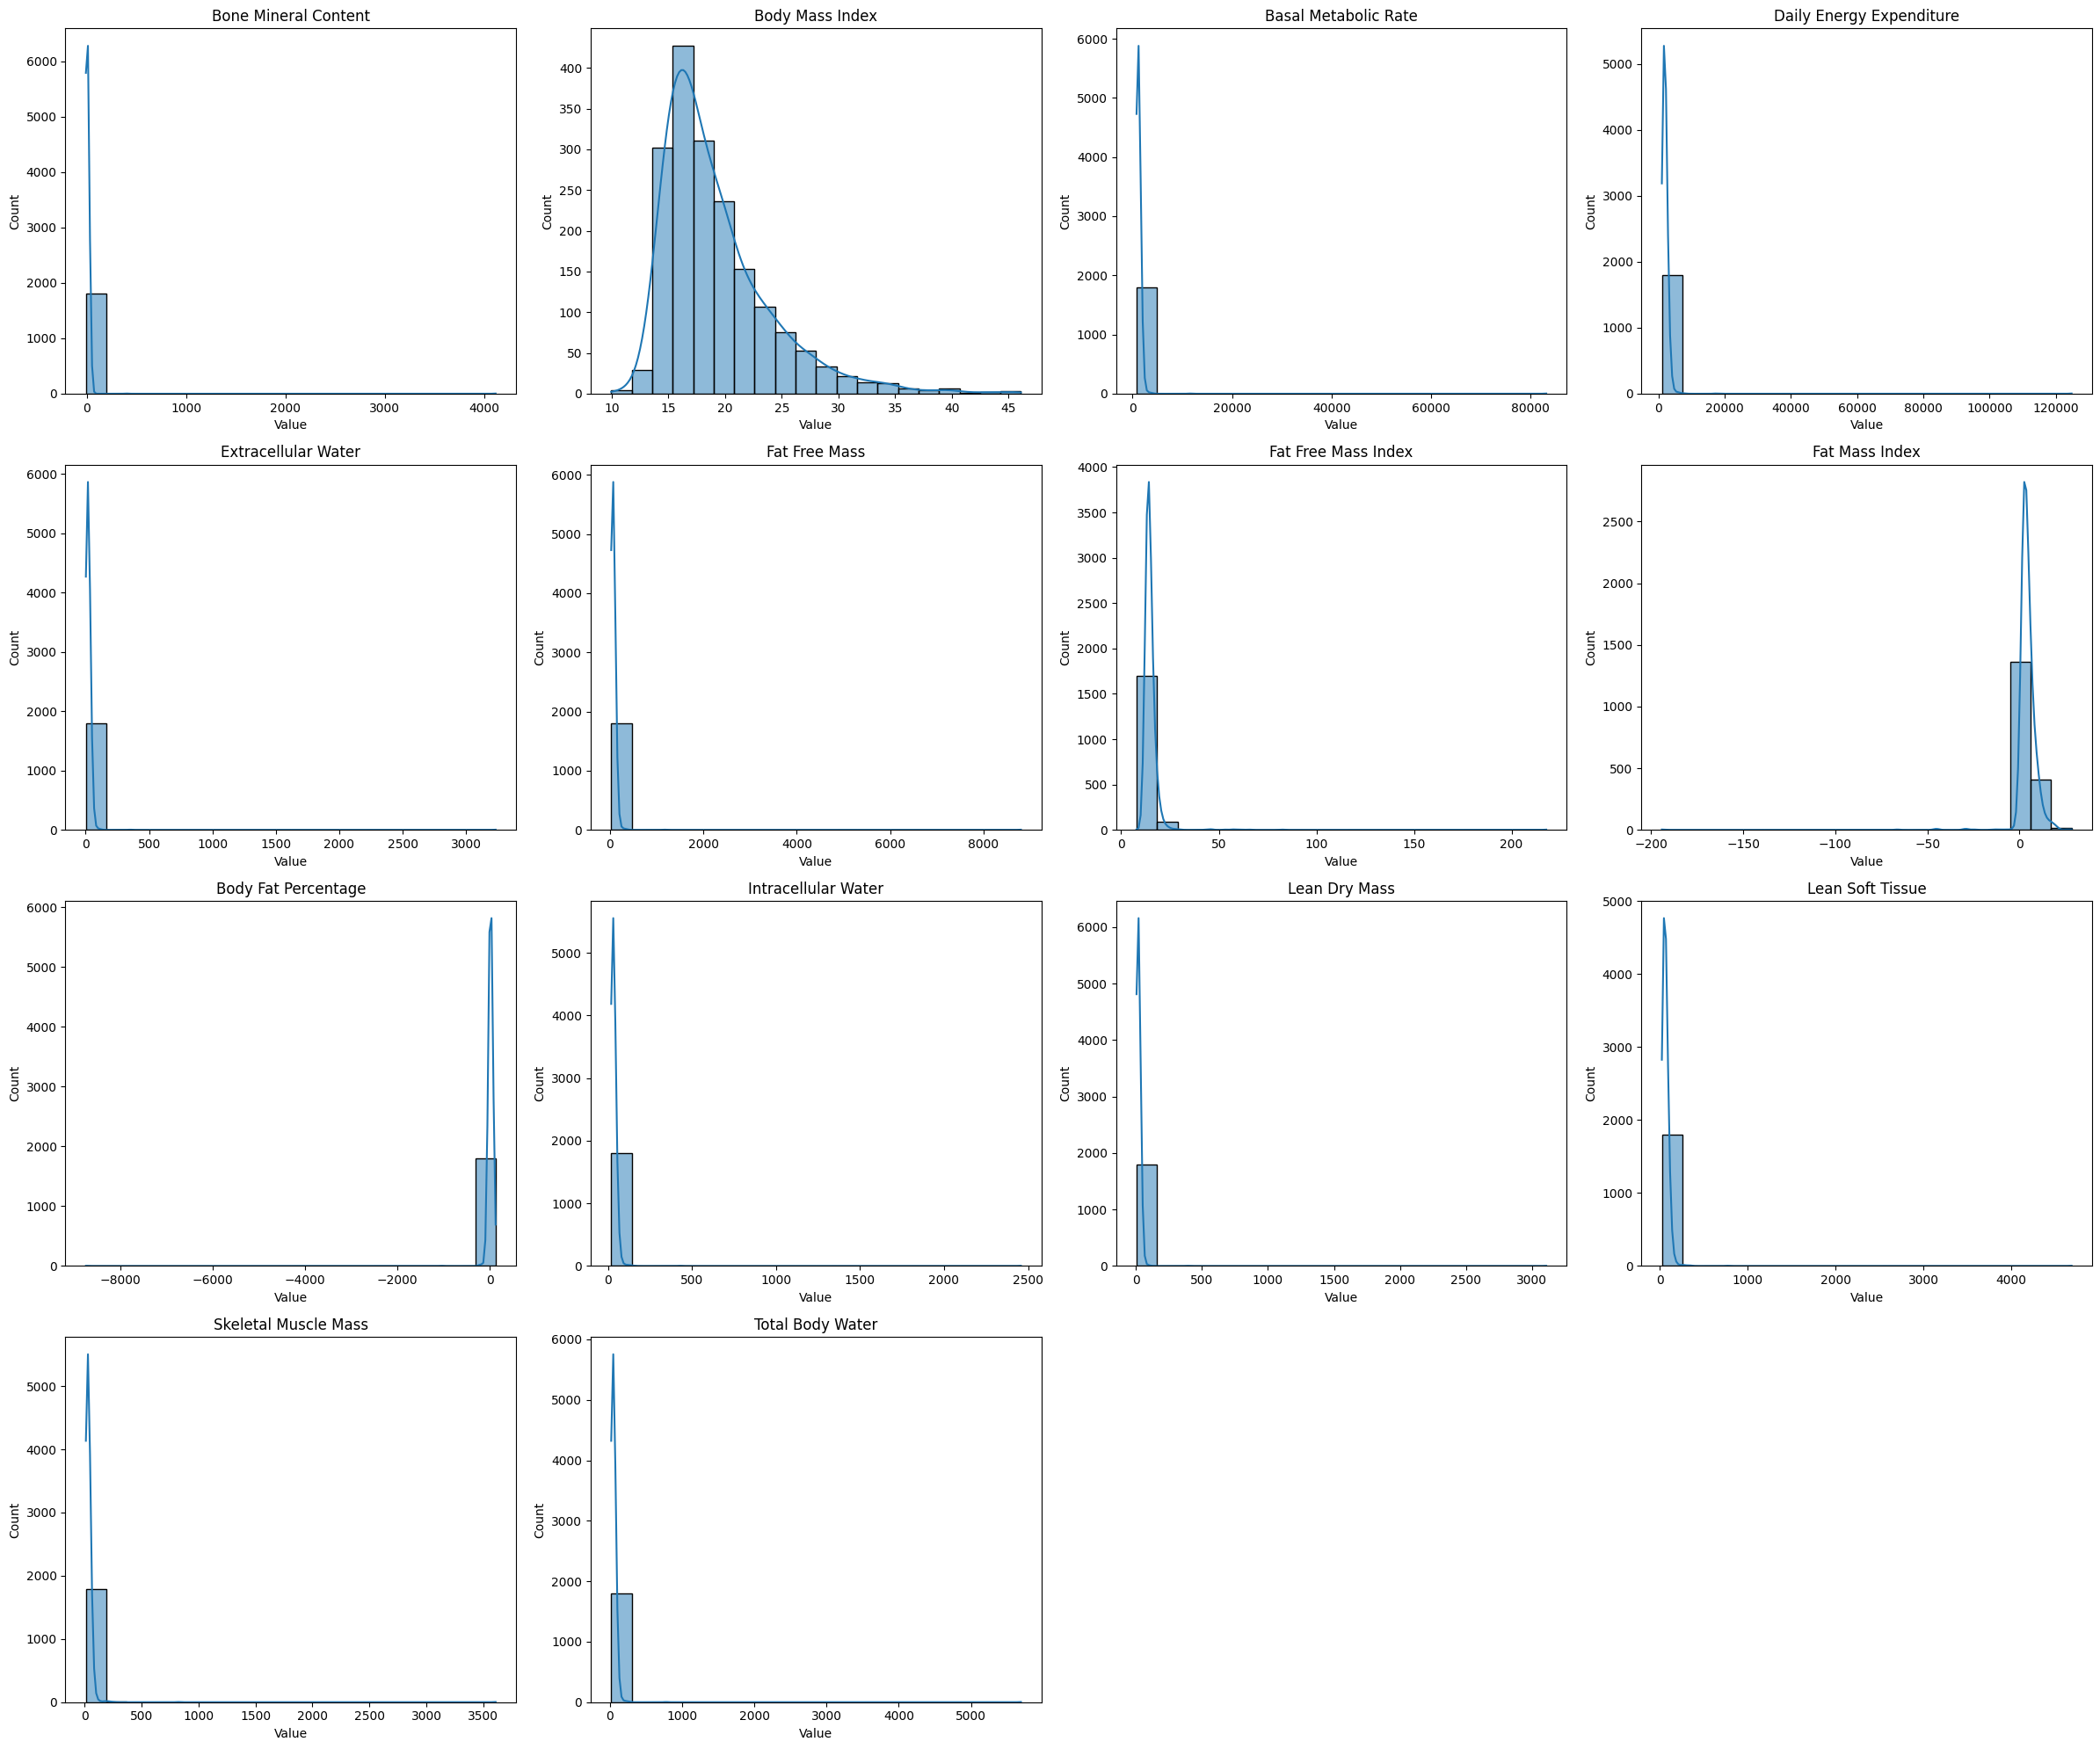

In [85]:
plt.figure(figsize=(24, 20))

for idx, col in enumerate(continuous_columns):
    plt.subplot(4, 4, idx + 1)
    sns.histplot(train[col].dropna(), bins=20, kde=True)
    plt.title(data_dict[data_dict['Field'] == col]['Description'].values[0])
    plt.xlabel('Value')

plt.tight_layout()
plt.show()

Only the BMI column seems reliable, the rest should be discarded

In [86]:
for col in continuous_columns:
    if (col != 'BIA-BIA_BMI'):
        train = train.drop(columns=col)
        test = test.drop(columns=col)

## Time series

In [87]:
def process_file(filename, dirname):
    df = pd.read_parquet(os.path.join(dirname, filename, 'part-0.parquet'))
    df.drop('step', axis=1, inplace=True)
    return df.describe().values.reshape(-1), filename.split('=')[1]

def load_time_series(dirname) -> pd.DataFrame:
    ids = os.listdir(dirname)

    with ThreadPoolExecutor() as executor:
        results = list(tqdm(executor.map(lambda fname: process_file(fname, dirname), ids), total=len(ids)))

    stats, indexes = zip(*results)

    df = pd.DataFrame(stats, columns=[f"stat_{i}" for i in range(len(stats[0]))])
    df['id'] = indexes
    return df

train_ts = load_time_series("/kaggle/input/child-mind-institute-problematic-internet-use/series_train.parquet")
test_ts = load_time_series("/kaggle/input/child-mind-institute-problematic-internet-use/series_test.parquet")

time_series_cols = train_ts.columns.tolist()
time_series_cols.remove("id")

train = pd.merge(train, train_ts, how="left", on='id')
test = pd.merge(test, test_ts, how="left", on='id')

train = train.drop('id', axis=1)
test = test.drop('id', axis=1)

100%|██████████| 2/2 [00:00<00:00,  6.69it/s]


## Other features

We will left other missing values intact for this notebook

In [88]:
imputer = KNNImputer(n_neighbors=10)

feature_numeric_cols = train.select_dtypes(include=['float64', 'int64', 'bool']).columns

columns_to_exclude = question_columns + ['PCIAT-PCIAT_Total', 'sii']

feature_numeric_cols = [col for col in feature_numeric_cols if col not in columns_to_exclude]

# Feature engineering

Encode unencoded season columns and drop String columns

In [89]:
encoded_season_cols = ['Basic_Demos-Enroll_Season', 'SDS-Season']
non_encoded_season_cols = ['CGAS-Season', 'Physical-Season', 'Fitness_Endurance-Season', 
          'FGC-Season', 'BIA-Season', 'PAQ_A-Season', 'PAQ_C-Season', 'PreInt_EduHx-Season']

def remove_encoded_cols(df):
    return df.drop(columns=encoded_season_cols + ['Age Group', 'index'])

train = remove_encoded_cols(train)
test = remove_encoded_cols(test)

def fillna_season(df):
    for c in non_encoded_season_cols: 
        df[c] = df[c].fillna('Missing')
        df[c] = df[c].astype('category')
    return df
        
train = fillna_season(train)
test = fillna_season(test)

def create_mapping(column, dataset):
    unique_values = dataset[column].unique()
    return {value: idx for idx, value in enumerate(unique_values)}

for col in non_encoded_season_cols:
    mapping_train = create_mapping(col, train)
    mapping_test = create_mapping(col, test)
    
    train[col] = train[col].replace(mapping_train).astype(int)
    test[col] = test[col].replace(mapping_test).astype(int)


train = train.drop(columns=question_columns + ['PCIAT-Season', 'PCIAT-PCIAT_Total'])

print(f'Train Shape : {train.shape} || Test Shape : {test.shape}')
train.head()

Train Shape : (2719, 149) || Test Shape : (20, 148)


,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMI,BIA-BIA_Frame_num,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,SDS-SDS_Total_Raw,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,Age_Group_Label,Season_Spring,Season_Summer,Basic_Demos-Age,Season_Fall,Season_Winter,Basic_Demos-Sex,Physical-Weight,Physical-Height,SDS-Season_Fall,SDS-Season_Spring,SDS-Season_Summer,SDS-Season_Winter,SDS_Weight,stat_0,stat_1,stat_2,stat_3,stat_4,stat_5,stat_6,stat_7,stat_8,stat_9,stat_10,stat_11,stat_12,stat_13,stat_14,stat_15,stat_16,stat_17,stat_18,stat_19,stat_20,stat_21,stat_22,stat_23,stat_24,stat_25,stat_26,stat_27,stat_28,stat_29,stat_30,stat_31,stat_32,stat_33,stat_34,stat_35,stat_36,stat_37,stat_38,stat_39,stat_40,stat_41,stat_42,stat_43,stat_44,stat_45,stat_46,stat_47,stat_48,stat_49,stat_50,stat_51,stat_52,stat_53,stat_54,stat_55,stat_56,stat_57,stat_58,stat_59,stat_60,stat_61,stat_62,stat_63,stat_64,stat_65,stat_66,stat_67,stat_68,stat_69,stat_70,stat_71,stat_72,stat_73,stat_74,stat_75,stat_76,stat_77,stat_78,stat_79,stat_80,stat_81,stat_82,stat_83,stat_84,stat_85,stat_86,stat_87,stat_88,stat_89,stat_90,stat_91,stat_92,stat_93,stat_94,stat_95
0,0,51.0,0,16.878972,58.833887,NaN,NaN,NaN,0,NaN,NaN,NaN,0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,0,2.0,16.879200,1.0,0,NaN,0,NaN,41.0,0,3.0,2.0,2,False,False,5.0,1.0,0.0,0.0,23.042474,116.84,False,False,True,False,0.354344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0,14.036968,55.880000,75.0,70.0,122.0,0,NaN,NaN,NaN,0,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,1,2.0,14.037100,1.0,0,NaN,1,2.340,46.0,1,0.0,0.0,2,False,True,9.0,0.0,0.0,0.0,20.865232,121.92,True,False,False,False,0.249740,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,71.0,0,16.650330,62.557763,65.0,94.0,117.0,1,5.0,7.0,33.0,0,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,2,NaN,NaN,NaN,0,NaN,2,2.170,38.0,1,2.0,0.0,2,False,True,10.0,0.0,0.0,1.0,34.291555,143.51,True,False,False,False,0.425557,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,71.0,1,18.294143,65.504753,60.0,97.0,117.0,2,6.0,9.0,37.0,1,18.0,1.0,NaN,NaN,NaN,NaN,5.0,0.0,7.0,0.0,7.0,0.0,7.0,1.0,3,3.0,18.294300,2.0,0,NaN,3,2.451,31.0,2,0.0,1.0,2,False,False,9.0,0.0,1.0,0.0,37.013107,142.24,False,False,True,False,0.598688,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,43330.0,-0.316384,0.016009,-0.167890,0.047388,-10.580416,0.000000,42.296310,4053.579102,5.046215e+13,4.470182,3.0,53.201683,0


This step is crucial as it creates new features by combining existing variables, capturing more complex relationships in the data. These engineered features, such as interactions between age, BMI, CGAS scores, and internet usage, are key for improving the predictive power of the model.

In [90]:
def feature_engineering(df):
    #Weight
    df['CGAS_Weight'] = df['CGAS-CGAS_Score'].apply(sigmoid_weight_cgas_high)
    df['SDS_Score_Weighted'] = df['SDS-SDS_Total_Raw'] * df['SDS_Weight']
    df['CGAS_Score_Weighted'] = df['CGAS-CGAS_Score'] * df['CGAS_Weight']
    df = df.drop(columns=['SDS-SDS_Total_Raw', 'SDS_Weight', 'CGAS-CGAS_Score', 'CGAS_Weight', 'Age_Group_Label'])
    
    #Age
    df['Internet_Hours_Age'] = df['PreInt_EduHx-computerinternet_hoursday'] * df['Basic_Demos-Age']
    df['Physical-Waist_Age'] = df['Basic_Demos-Age'] * df['Physical-Waist_Circumference']
    df['BMI_Age'] = df['Physical-BMI'] * df['Basic_Demos-Age']
    df['Physical-Height_Age'] = df['Basic_Demos-Age'] * df['Physical-Height']

    #SDS
    df['SDS_BMI'] = df['Physical-BMI'] * df['SDS_Score_Weighted']
    df['CGAS_SDS'] = df['CGAS_Score_Weighted'] * df['SDS_Score_Weighted']
    df['CGAS_Endurance_Mins'] = df['CGAS_Score_Weighted'] * df['Fitness_Endurance-Time_Mins']
    df['SDS_Activity'] = df['BIA-BIA_Activity_Level_num'] * df['SDS_Score_Weighted']
    df['SDS_InternetHours'] = df['SDS_Score_Weighted'] * df['PreInt_EduHx-computerinternet_hoursday']

    df['BMI_Systolic_BP'] = df['Physical-BMI'] * df['Physical-Systolic_BP']
    df['Age_Systolic_BP'] = df['Basic_Demos-Age'] * df['Physical-Systolic_BP']
    df['PreInt_Systolic_BP'] = df['Physical-Systolic_BP'] * df['PreInt_EduHx-computerinternet_hoursday']
    df['PAQ_A_Activity'] = df['BIA-BIA_Activity_Level_num'] * df['PAQ_A-PAQ_A_Total']
    df['Activity_CU_PU'] = df['BIA-BIA_Activity_Level_num'] * df['FGC-FGC_CU'] * df['FGC-FGC_PU']

    #FGC
    df['FGC_CU_PU'] = df['FGC-FGC_CU'] * df['FGC-FGC_PU']
    df['FGC_CU_PU_Age'] = df['FGC-FGC_CU'] * df['FGC-FGC_PU'] * df['Basic_Demos-Age']
    df['FGC_GSND_GSD'] = df['FGC-FGC_GSND'] * df['FGC-FGC_GSD']
    df['FGC_GSND_GSD_Age'] = df['FGC-FGC_GSND'] * df['FGC-FGC_GSD'] * df['Basic_Demos-Age']
    df['CGAS_CU_PU'] = df['CGAS_Score_Weighted'] * df['FGC-FGC_CU'] * df['FGC-FGC_PU']
    df['PreInt_FGC_CU_PU'] = df['PreInt_EduHx-computerinternet_hoursday'] * df['FGC-FGC_CU'] * df['FGC-FGC_PU']
    df['Endurance_CU_PU'] = df['Fitness_Endurance-Time_Mins'] * df['FGC-FGC_CU'] * df['FGC-FGC_PU']
    return df

train = feature_engineering(train)
test = feature_engineering(test)

new_features = ['Internet_Hours_Age', 'Physical-Waist_Age', 'BMI_Age', 'Physical-Height_Age', 'SDS_InternetHours', 'SDS_BMI', 'CGAS_SDS', 'CGAS_Endurance_Mins', 'SDS_Activity', 'BMI_Systolic_BP', 'Age_Systolic_BP', 'PreInt_Systolic_BP', 'PAQ_A_Activity', 'Activity_CU_PU', 'FGC_CU_PU', 'FGC_CU_PU_Age', 'FGC_GSND_GSD', 'FGC_GSND_GSD_Age', 'CGAS_CU_PU', 'PreInt_FGC_CU_PU', 'Endurance_CU_PU', 'CGAS_Weight', 'SDS_Score_Weighted', 'CGAS_Score_Weighted']

# Parameters Setting

In [91]:
from sklearn.linear_model import Ridge
from sklearn.svm import SVR

SEED = 42
n_splits = 5

In [92]:
LGB_Params = {
    'learning_rate': 0.046,
    'max_depth': 12,
    'num_leaves': 478,
    'min_data_in_leaf': 13,
    'feature_fraction': 0.893,
    'bagging_fraction': 0.784,
    'bagging_freq': 4,
    'lambda_l1': 10,
    'lambda_l2': 0.01
}

CatBoost_Params = {
    'learning_rate': 0.05,
    'depth': 6,
    'iterations': 200,
    'random_seed': SEED,
    'verbose': 0,
    'l2_leaf_reg': 10,
    'task_type': 'GPU'
}

XGB_Params = {
    'learning_rate': 0.05,
    'max_depth': 6,
    'n_estimators': 200,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 1,  
    'reg_lambda': 3,  
    'random_state': SEED,
    'tree_method': 'gpu_hist',
}

XGB_Params.update({
    'learning_rate': 0.01,
    'max_depth': 5,
    'n_estimators': 500,
    'reg_alpha': 5,
    'reg_lambda': 10,
})

# Model definition

In [93]:
LGB_Model = LGBMRegressor(**LGB_Params, random_state=SEED, verbose=-1, n_estimators=300)
CatBoost_Model = CatBoostRegressor(**CatBoost_Params)
XGB_Model = XGBRegressor(**XGB_Params)

# Train and predict

In [94]:
print(train.shape)
train.head()

(2719, 168)


,CGAS-Season,Physical-Season,Physical-BMI,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMI,BIA-BIA_Frame_num,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,Season_Spring,Season_Summer,Basic_Demos-Age,Season_Fall,Season_Winter,Basic_Demos-Sex,Physical-Weight,Physical-Height,SDS-Season_Fall,SDS-Season_Spring,SDS-Season_Summer,SDS-Season_Winter,stat_0,stat_1,stat_2,stat_3,stat_4,stat_5,stat_6,stat_7,stat_8,stat_9,stat_10,stat_11,stat_12,stat_13,stat_14,stat_15,stat_16,stat_17,stat_18,stat_19,stat_20,stat_21,stat_22,stat_23,stat_24,stat_25,stat_26,stat_27,stat_28,stat_29,stat_30,stat_31,stat_32,stat_33,stat_34,stat_35,stat_36,stat_37,stat_38,stat_39,stat_40,stat_41,stat_42,stat_43,stat_44,stat_45,stat_46,stat_47,stat_48,stat_49,stat_50,stat_51,stat_52,stat_53,stat_54,stat_55,stat_56,stat_57,stat_58,stat_59,stat_60,stat_61,stat_62,stat_63,stat_64,stat_65,stat_66,stat_67,stat_68,stat_69,stat_70,stat_71,stat_72,stat_73,stat_74,stat_75,stat_76,stat_77,stat_78,stat_79,stat_80,stat_81,stat_82,stat_83,stat_84,stat_85,stat_86,stat_87,stat_88,stat_89,stat_90,stat_91,stat_92,stat_93,stat_94,stat_95,SDS_Score_Weighted,CGAS_Score_Weighted,Internet_Hours_Age,Physical-Waist_Age,BMI_Age,Physical-Height_Age,SDS_BMI,CGAS_SDS,CGAS_Endurance_Mins,SDS_Activity,SDS_InternetHours,BMI_Systolic_BP,Age_Systolic_BP,PreInt_Systolic_BP,PAQ_A_Activity,Activity_CU_PU,FGC_CU_PU,FGC_CU_PU_Age,FGC_GSND_GSD,FGC_GSND_GSD_Age,CGAS_CU_PU,PreInt_FGC_CU_PU,Endurance_CU_PU
0,0,0,16.878972,58.833887,NaN,NaN,NaN,0,NaN,NaN,NaN,0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,0,2.0,16.879200,1.0,0,NaN,0,NaN,0,3.0,2.0,False,False,5.0,1.0,0.0,0.0,23.042474,116.84,False,False,True,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.528091,0.153939,15.0,294.169435,84.394862,584.20,245.219254,2.236443,NaN,29.056183,43.584274,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,0.000000,0.0,NaN
1,1,0,14.036968,55.880000,75.0,70.0,122.0,0,NaN,NaN,NaN,0,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,1,2.0,14.037100,1.0,0,NaN,1,2.340,1,0.0,0.0,False,True,9.0,0.0,0.0,0.0,20.865232,121.92,True,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.488035,NaN,0.0,502.920000,126.332712,1097.28,161.257182,NaN,NaN,22.976070,0.000000,1712.510097,1098.0,0.0,NaN,30.0,15.0,135.0,NaN,NaN,NaN,0.0,NaN
2,1,0,16.650330,62.557763,65.0,94.0,117.0,1,5.0,7.0,33.0,0,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,2,NaN,NaN,NaN,0,NaN,2,2.170,1,2.0,0.0,False,True,10.0,0.0,0.0,1.0,34.291555,143.51,True,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

In [95]:
print(test.shape)
test.head()

(20, 167)


,CGAS-Season,Physical-Season,Physical-BMI,Physical-Waist_Circumference,Physical-Diastolic_BP,Physical-HeartRate,Physical-Systolic_BP,Fitness_Endurance-Season,Fitness_Endurance-Max_Stage,Fitness_Endurance-Time_Mins,Fitness_Endurance-Time_Sec,FGC-Season,FGC-FGC_CU,FGC-FGC_CU_Zone,FGC-FGC_GSND,FGC-FGC_GSND_Zone,FGC-FGC_GSD,FGC-FGC_GSD_Zone,FGC-FGC_PU,FGC-FGC_PU_Zone,FGC-FGC_SRL,FGC-FGC_SRL_Zone,FGC-FGC_SRR,FGC-FGC_SRR_Zone,FGC-FGC_TL,FGC-FGC_TL_Zone,BIA-Season,BIA-BIA_Activity_Level_num,BIA-BIA_BMI,BIA-BIA_Frame_num,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,Season_Spring,Season_Summer,Basic_Demos-Age,Season_Fall,Season_Winter,Basic_Demos-Sex,Physical-Weight,Physical-Height,SDS-Season_Fall,SDS-Season_Spring,SDS-Season_Summer,SDS-Season_Winter,stat_0,stat_1,stat_2,stat_3,stat_4,stat_5,stat_6,stat_7,stat_8,stat_9,stat_10,stat_11,stat_12,stat_13,stat_14,stat_15,stat_16,stat_17,stat_18,stat_19,stat_20,stat_21,stat_22,stat_23,stat_24,stat_25,stat_26,stat_27,stat_28,stat_29,stat_30,stat_31,stat_32,stat_33,stat_34,stat_35,stat_36,stat_37,stat_38,stat_39,stat_40,stat_41,stat_42,stat_43,stat_44,stat_45,stat_46,stat_47,stat_48,stat_49,stat_50,stat_51,stat_52,stat_53,stat_54,stat_55,stat_56,stat_57,stat_58,stat_59,stat_60,stat_61,stat_62,stat_63,stat_64,stat_65,stat_66,stat_67,stat_68,stat_69,stat_70,stat_71,stat_72,stat_73,stat_74,stat_75,stat_76,stat_77,stat_78,stat_79,stat_80,stat_81,stat_82,stat_83,stat_84,stat_85,stat_86,stat_87,stat_88,stat_89,stat_90,stat_91,stat_92,stat_93,stat_94,stat_95,SDS_Score_Weighted,CGAS_Score_Weighted,Internet_Hours_Age,Physical-Waist_Age,BMI_Age,Physical-Height_Age,SDS_BMI,CGAS_SDS,CGAS_Endurance_Mins,SDS_Activity,SDS_InternetHours,BMI_Systolic_BP,Age_Systolic_BP,PreInt_Systolic_BP,PAQ_A_Activity,Activity_CU_PU,FGC_CU_PU,FGC_CU_PU_Age,FGC_GSND_GSD,FGC_GSND_GSD_Age,CGAS_CU_PU,PreInt_FGC_CU_PU,Endurance_CU_PU
0,0,0,16.878972,58.833887,NaN,NaN,NaN,0,NaN,NaN,NaN,0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,7.0,0.0,6.0,0.0,6.0,1.0,0,2.0,16.8792,1.0,0,NaN,0,NaN,0,3.0,False,False,5.0,1.0,0.0,0.0,23.042474,116.8400,True,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.021604,0.153939,15.0,294.169435,84.394862,584.2000,236.670268,2.158475,NaN,28.043208,42.064812,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,0.000000,0.0,NaN
1,1,0,14.036968,55.880000,75.0,70.0,122.0,0,NaN,NaN,NaN,0,3.0,0.0,NaN,NaN,NaN,NaN,5.0,0.0,11.0,1.0,11.0,1.0,3.0,0.0,1,2.0,14.0371,1.0,0,NaN,1,2.340,1,0.0,False,True,9.0,0.0,0.0,0.0,20.865232,121.9200,True,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.488035,NaN,0.0,502.920000,126.332712,1097.2800,161.257182,NaN,NaN,22.976070,0.000000,1712.510097,1098.0,0.0,NaN,30.0,15.0,135.0,NaN,NaN,NaN,0.0,NaN
2,2,0,16.650330,62.557763,65.0,94.0,117.0,1,5.0,7.0,33.0,0,20.0,1.0,10.2,1.0,14.7,2.0,7.0,1.0,10.0,1.0,10.0,1.0,5.0,0.0,2,NaN,NaN,NaN,0,NaN,2,2.170,1,2.0,False,True,10.0,0.0,0.0,1.0,34.291555,143.5100,True,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

Simple model

In [96]:
simple_features = ['SDS_Score_Weighted', 'Internet_Hours_Age', 'Physical-Height_Age', 
                  'Basic_Demos-Sex', 'PreInt_FGC_CU_PU']

train = train[simple_features + ['sii']]
test = test[simple_features]

Show features imporatance for XGB, LGB and CatBoost models

In [97]:
def show_feature_importance(model, model_type='xgb'):
    if model_type == 'xgb':  # XGBoost
        booster = model.get_booster()
        feature_importance = booster.get_score(importance_type='gain')
        feature_importance_df = pd.DataFrame({
            'Feature': list(feature_importance.keys()),
            'Importance': list(feature_importance.values())
        })

    elif model_type == 'lgb':  # LightGBM
        feature_importance_df = pd.DataFrame({
            'Feature': model.feature_name_,
            'Importance': model.feature_importances_
        })

    elif model_type == 'catboost':  # CatBoost
        feature_importance = model.get_feature_importance()
        feature_importance_df = pd.DataFrame({
            'Feature': model.feature_names_,
            'Importance': feature_importance
        })

    else:
        raise ValueError("model_type must be 'xgb', 'lgb', or 'catboost'")
    
    # Sắp xếp theo tầm quan trọng
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

    # Visualization
    plt.figure(figsize=(20, 40))
    sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
    plt.title("Top Feature Importance")
    plt.show()

In [98]:
sample = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/sample_submission.csv')

## XGB

In [99]:
# Submission1,new_XGB_Model = TrainML(XGB_Model, train, test)
# show_feature_importance(new_XGB_Model, model_type='xgb')

In [100]:
# Submission1

## LGB

In [101]:
# Submission2,new_LGB_Model = TrainML(LGB_Model, train, test)
# show_feature_importance(new_LGB_Model, model_type='lgb')

In [102]:
# Submission2

## CatBoost

In [103]:
# Submission3,new_Cat_Model = TrainML(CatBoost_Model, train, test)
# show_feature_importance(new_Cat_Model, model_type='catboost')

In [104]:
# Submission3

## Ensemble Model

Models are combined using a Stacking Regressor, and a Voting Regressor is used to combine the stacked model for ensemble predictions

In [105]:
estimators = [
    ('catboost', CatBoost_Model),
    ('lightgbm', LGB_Model),
    ('xgboost', XGB_Model),
    # ('tabnet', TabNet_Model),
    # ('ridge', ridge_pipeline),
    # ('svr', svr_pipeline)
]

# StackingRegressor
ensemble_model = StackingRegressor(
    estimators=estimators,
    # final_estimator=GradientBoostingRegressor(n_estimators=50, learning_rate=0.1),
    # cv=5  
)

final_submission,new_ensemble_model = TrainML(ensemble_model, train, test)

Training Folds: 100%|██████████| 5/5 [01:07<00:00, 13.54s/it]

Mean Train QWK --> 0.4735
Mean Validation QWK ---> 0.3976


----> || Optimized QWK SCORE ::  0.476


In [106]:
final_submission

,id,sii
0,00008ff9,0
1,000fd460,0
2,00105258,0
3,00115b9f,0
4,0016bb22,2
5,001f3379,0
6,0038ba98,0
7,0068a485,0
8,0069fbed,2
9,0083e397,1


# Submission

In [107]:
final_submission[['id', 'sii']].to_csv('submission.csv', index=False)

# Credit

EDA from https://www.kaggle.com/code/antoninadolgorukova/cmi-piu-features-eda

Time series data EDA and threshold tuning methods from https://www.kaggle.com/code/ambrosm/piu-eda-which-makes-sense